# Ejercicio Práctico — Semana 1: Pipeline reproducible de ML: uso de redes sociales y bienestar emocional

**Asignatura:** Inteligencia Artificial: Data Mining II — Maestría en Ciencias de Datos y Máquinas de Aprendizaje, mención IA (UIDE)
**Docente:** Miguel Angel Rosero Aguas
**Cubre:** Sesión 1 — NumPy, pandas 3 y un Pipeline sin fuga de información  /  Sesión 2 — Modelado, validación y evaluación con scikit-learn
**Grupo N.º:** 10  
**Fecha:** 27/10/2026  
**Semilla:** 42 · versiones de librerías registradas en la fase 1

| # | Integrante | Rol en el equipo |
|---|---|---|
| 1 | | |
| 2 | | |
| 3 | | |
| 4 | | |

## Índice

1. [Carga, calidad de datos y decisiones de limpieza](#fase-1)
2. [Análisis exploratorio (EDA)](#fase-2)
3. [Análisis de regresión](#fase-3)
4. [Pipeline de preprocesamiento: escalado, normalización y codificación](#fase-4)
5. [Clustering con el pipeline (PCA + DBSCAN)](#fase-5)
6. [Selección de características y reducción de dimensionalidad](#fase-6)
7. [Clasificación supervisada y ajuste de hiperparámetros](#fase-7)
8. [Plus (opcional): lo que va más allá del sílabo](#fase-8)
9. [Desafío y registro de decisiones](#fase-9)
10. [Tendencias: de pandas a Polars y DuckDB](#fase-10)
11. [Fase final: aplicación al entorno profesional](#fase-final)

## Estructura del ejercicio

Este notebook va con la guía **Ejercicio_Practico_Semana1_Guia.docx**: el código y los gráficos se hacen aquí; en la guía responden por escrito
la **pregunta de cada fase** (la misma que aparece abajo de cada título) y la fase final individual.

| Bloque | Fases | Qué entregan |
|---|---|---|
| Datos y exploración | 1–3 | código + conclusión en el notebook; respuesta en la guía |
| Modelado y análisis | 4–7 | código + conclusión en el notebook; respuesta en la guía |
| Desafío y tendencias | 8–9 | evidencia en el notebook; respuesta en la guía |
| Aplicación profesional | final | una respuesta por integrante (notebook y guía) |

**Entrega en Canvas:** este notebook ejecutado y la guía completada (Word o PDF).

## Contexto

Una startup de bienestar digital quiere entender si los hábitos en redes sociales (tiempo de uso, publicaciones, likes, comentarios, mensajes, plataforma) se relacionan con la emoción dominante que reportan sus usuarios. Ustedes son el equipo de datos: deben entregar un **flujo reproducible** de preparación, modelado y evaluación con NumPy, Pandas y scikit-learn, que otro equipo pueda volver a ejecutar y obtener los mismos resultados.

**Dataset:** Social Media Usage and Emotional Well-Being (Kaggle, emirhanai): https://www.kaggle.com/datasets/emirhanai/social-media-usage-and-emotional-well-being

## Desafío

1) Entregar un **pipeline único de scikit-learn** (preprocesamiento + selección/reducción + modelo) ajustado sin fuga de información, con métricas de prueba calculadas **una sola vez**. 2) Con evidencia del análisis, identificar el **perfil de usuario con mayor riesgo de emoción negativa** (Anxiety, Sadness o Anger) y recomendar **una** intervención piloto. 3) Declarar una **limitación seria del dataset** y una **implicación ética** que la startup debe conocer antes de invertir.

> **Formato de entrega:** un único `.ipynb` ejecutado. Código limpio y comentado. Antes de cada gráfico,
> una línea que diga qué se analiza; después, la conclusión de negocio. Nombre del archivo:
> `grupoN_Semana1_Ejercicio.ipynb`.

In [1]:
# ===== Entorno: el mismo notebook corre en Google Colab y en local =====
import importlib, importlib.util, os, shutil, subprocess, sys, urllib.request   # utilidades: instalar paquetes, rutas y descargas
from pathlib import Path                            # rutas iguales en Windows, Linux y Colab

EN_COLAB = "google.colab" in sys.modules           # True si estamos dentro de Colab
print("Entorno:", "Google Colab" if EN_COLAB else "local", "| Python", sys.version.split()[0])   # dónde corre y qué Python

# Instalamos solo los paquetes que falten. El nombre en pip no siempre es el del import
IMPORT_DE = {"scikit-learn": "sklearn", "imbalanced-learn": "imblearn"}   # nombre en pip -> nombre del import
for pip_nombre in ['kagglehub', 'polars', 'duckdb', 'pyarrow', 'optuna', 'imbalanced-learn', 'scikit-learn']:   # paquetes de esta práctica
    modulo = IMPORT_DE.get(pip_nombre, pip_nombre.replace("-", "_"))   # nombre del import
    if importlib.util.find_spec(modulo) is None:   # solo si NO está instalado (Colab ya trae muchos)
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_nombre])   # Colab y venv con pip
        if r.returncode != 0 and shutil.which("uv"):                   # venv creado con uv (no trae pip)
            r = subprocess.run(["uv", "pip", "install", "-q", "--python", sys.executable, pip_nombre])
        if r.returncode != 0:
            raise RuntimeError(f"Instala '{pip_nombre}' en este entorno (pip/uv) y vuelve a ejecutar")
        importlib.invalidate_caches()                                  # para que el import vea el paquete recién instalado

# Carpeta de datos relativa: en Colab es /content/data, en local ./data
DATA = Path("data"); DATA.mkdir(exist_ok=True)   # crea la carpeta si no existe

def descargar(url, nombre):   # Ej.: descargar(URL, "train.csv") -> data/train.csv
    # Descarga una sola vez; si el archivo ya existe, no vuelve a bajarlo
    destino = DATA / nombre
    if not destino.exists():
        print("Descargando", nombre, "...")
        urllib.request.urlretrieve(url, destino)
    return destino

# Respaldo si Kaggle no está disponible: copia pública en GitHub de los CSV originales de Kaggle (train y test)
RESPALDO_GITHUB = "https://raw.githubusercontent.com/serieh/emotion-engine/main/data/"


Entorno: Google Colab | Python 3.13.16


In [2]:
# ===== Estilo de gráficos (principios de Tufte): poca tinta, un solo color de acento =====
import matplotlib.pyplot as plt                     # gráficos
from cycler import cycler                           # orden de colores por defecto
TINTA, ACENTO, GRIS = "#14323F", "#1A9FB0", "#B7C3C9"     # tokens del módulo; ACENTO = color de esta semana
plt.rcParams.update({   # estilo por defecto de todos los gráficos
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "axes.edgecolor": GRIS,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlecolor": TINTA,
    "axes.prop_cycle": cycler(color=[TINTA, ACENTO, GRIS, "#5B6B73"]),
    "font.size": 11, "legend.frameon": False, "figure.dpi": 110,
})
NEGATIVAS = ['Anxiety', 'Sadness', 'Anger']          # emociones de riesgo del desafío (se usan en varias fases)
color_emocion = lambda e: ACENTO if e in NEGATIVAS else GRIS   # acento = emoción negativa


<a id="fase-1"></a>
## Fase 1: Carga, calidad de datos y decisiones de limpieza

Pasos 1–2 del enunciado. Carguen train/val/test en DataFrames, revisen tipos, nulos y valores inconsistentes. **Pista:** revisen los valores únicos de `Age`, `Gender` y `Dominant_Emotion` antes de convertir tipos: el dataset trae errores reales de captura. **pandas 3:** limpien reasignando columnas (`df['col'] = df['col'].fillna(...)`), nunca con asignación encadenada + `inplace=True`, que con Copy-on-Write no modifica el DataFrame; comparen la memoria con `dtype_backend="pyarrow"`. Cada decisión de limpieza va al registro de decisiones (fase 8).

> **Pregunta de la guía:** ¿Qué errores de captura encontraron en Age, Gender y Dominant_Emotion y qué decidieron con cada uno?

**Qué analizamos:** cargamos train/val/test, miramos tipos y valores únicos de `Age`, `Gender` y `Dominant_Emotion` para encontrar errores de captura, limpiamos con reglas explícitas (reasignando columnas, como exige pandas 3), cuantificamos duplicados y medimos la memoria con Arrow.

In [3]:
# Reproducibilidad: fijamos semilla y registramos versiones de las librerías
import sys, time, warnings, numpy as np, pandas as pd, sklearn
SEMILLA = 42                                        # una sola semilla para todo el notebook
np.random.seed(SEMILLA)
print('Python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)

# Fuente de datos, en orden: 1) carpeta data/ si ya están los CSV; 2) kagglehub; 3) copia pública en GitHub
if (DATA / 'train.csv').exists():
    ruta = DATA; print('Fuente: carpeta local data/')
else:
    try:
        import kagglehub
        ruta = Path(kagglehub.dataset_download('emirhanai/social-media-usage-and-emotional-well-being'))
        print('Fuente: Kaggle ->', ruta)
    except Exception as e:                           # sin credenciales o sin red hacia Kaggle
        print('kagglehub no disponible:', type(e).__name__, '-> uso la copia de GitHub (train y test originales)')
        for nombre in ['train.csv', 'test.csv']:
            descargar(RESPALDO_GITHUB + nombre, nombre)
        ruta = DATA

def leer(nombre):
    # Busca el archivo dentro de la carpeta descargada (Kaggle a veces lo anida) y lo lee
    candidatos = sorted(Path(ruta).rglob(nombre))
    if not candidatos:
        return None
    return pd.read_csv(candidatos[0], on_bad_lines='warn')   # warn: avisa de filas mal formadas en vez de fallar

train_raw, val_raw, test_raw = leer('train.csv'), leer('val.csv'), leer('test.csv')
for nombre, d in [('train', train_raw), ('val', val_raw), ('test', test_raw)]:
    print(f'{nombre:5s}:', d.shape if d is not None else 'no disponible en esta fuente')
train_raw.info()                                    # tipos: Age llega como TEXTO -> hay algo raro


Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1


100%|██████████| 8.34k/8.34k [00:00<00:00, 14.9MB/s]

Extracting files...
Fuente: Kaggle -> /root/.cache/kagglehub/datasets/emirhanai/social-media-usage-and-emotional-well-being/versions/1
train: (1001, 10)
val  : (145, 10)
test : (103, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001 entries, 0 to 1000
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   User_ID                     1001 non-null   object 
 1   Age                         1001 non-null   object 
 2   Gender                      1000 non-null   object 
 3   Platform                    1000 non-null   object 
 4   Daily_Usage_Time (minutes)  1000 non-null   float64
 5   Posts_Per_Day               1000 non-null   float64
 6   Likes_Received_Per_Day      1000 non-null   float64
 7   Comments_Received_Per_Day   1000 non-null   float64
 8   Messages_Sent_Per_Day       1000 non-null   float64
 9   Dominant_Emotion            1000 non-null   object 
dtypes: float64(5), ob


/tmp/ipykernel_1129/3236592518.py:26: ParserWarning: Skipping line 91: expected 10 fields, saw 11
Skipping line 159: expected 10 fields, saw 11
Skipping line 201: expected 10 fields, saw 11

  return pd.read_csv(candidatos[0], on_bad_lines='warn')   # warn: avisa de filas mal formadas en vez de fallar


In [4]:
# Valores únicos ANTES de convertir tipos (pista del enunciado): aquí aparecen los errores de captura
for col in ['Age', 'Gender', 'Dominant_Emotion']:
    vc = train_raw[col].value_counts(dropna=False)
    print(f'\n{col}: {len(vc)} valores distintos')
    print(vc.to_string())
print('\nNulos por columna (train):'); print(train_raw.isna().sum()[lambda s: s > 0])
print('\nFila con texto basura (salida de un generador de texto en turco):')
print(train_raw[pd.to_numeric(train_raw['Age'], errors='coerce').isna() & ~train_raw['Age'].isin(['Male', 'Female', 'Non-binary'])])



Age: 19 valores distintos
Age
28                                                      92
27                                                      92
29                                                      90
22                                                      74
26                                                      66
24                                                      64
25                                                      64
31                                                      62
21                                                      56
33                                                      56
30                                                      48
23                                                      48
35                                                      38
32                                                      38
34                                                      36
Male                                                    28
Female                   

In [5]:
# Limpieza explícita y reproducible: cada regla es de NEGOCIO (no aprende nada de los datos) -> no hay fuga
TARGET = 'Dominant_Emotion'
num = ['Age', 'Daily_Usage_Time (minutes)', 'Posts_Per_Day', 'Likes_Received_Per_Day',
       'Comments_Received_Per_Day', 'Messages_Sent_Per_Day']          # columnas numéricas
cat = ['Gender', 'Platform']                                           # categóricas sin orden
GENEROS = ['Male', 'Female', 'Non-binary']

def limpiar(d, nombre):
    d = d.copy()                                                       # nunca tocamos el DataFrame crudo
    es_num = lambda s: pd.to_numeric(s, errors='coerce').notna()
    # 1) Age y Gender intercambiadas: Age trae el género y Gender trae la edad -> las devolvemos a su sitio
    edad0 = d['Age'].astype('string').str.strip()                     # columnas originales como texto
    genero0 = d['Gender'].astype('string').str.strip()
    cruzadas = edad0.isin(GENEROS) & es_num(genero0)
    # 2) Tipos: reasignando columnas completas (pandas 3 / Copy-on-Write), nunca con inplace encadenado
    d['Age'] = pd.to_numeric(edad0.where(~cruzadas, genero0), errors='coerce')
    d['Gender'] = genero0.where(~cruzadas, edad0)
    for c in num[1:]:
        d[c] = pd.to_numeric(d[c], errors='coerce')
    # 3) Valores imposibles -> NaN (se imputan dentro del Pipeline). Raros se conservan.
    d['Age'] = d['Age'].where(d['Age'].between(13, 100))               # edad fuera de 13-100: imposible
    d['Daily_Usage_Time (minutes)'] = d['Daily_Usage_Time (minutes)'].where(d['Daily_Usage_Time (minutes)'].between(0, 1440))
    for c in num[2:]:
        d[c] = d[c].where(d[c] >= 0)                                   # conteos negativos: imposibles
    # 4) Filas sin etiqueta o sin ningún dato válido (la línea de texto basura) -> se eliminan
    basura = d[TARGET].isna() | d[num].isna().all(axis=1)
    print(f'{nombre:5s}: Age/Gender intercambiadas = {cruzadas.sum():3d} | filas basura o sin etiqueta = {basura.sum()} | '
          f'imposibles -> NaN = {int(d[num].isna().sum().sum() - d.loc[basura, num].isna().sum().sum())}')
    return d.loc[~basura].drop(columns='User_ID').reset_index(drop=True)

train_lim = limpiar(train_raw, 'train')
test = limpiar(test_raw, 'test')
val_lim = limpiar(val_raw, 'val') if val_raw is not None else None
print('\nGender tras limpiar:', train_lim['Gender'].value_counts().to_dict())
print('Dominant_Emotion tras limpiar:', train_lim[TARGET].value_counts().to_dict())


train: Age/Gender intercambiadas =  76 | filas basura o sin etiqueta = 1 | imposibles -> NaN = 0
test : Age/Gender intercambiadas =   1 | filas basura o sin etiqueta = 0 | imposibles -> NaN = 0
val  : Age/Gender intercambiadas =  12 | filas basura o sin etiqueta = 1 | imposibles -> NaN = 0

Gender tras limpiar: {'Female': 370, 'Male': 360, 'Non-binary': 270}
Dominant_Emotion tras limpiar: {'Happiness': 200, 'Neutral': 200, 'Anxiety': 170, 'Sadness': 160, 'Boredom': 140, 'Anger': 130}


In [6]:
# Duplicados: el mismo usuario (mismos 9 valores) repetido con distinto User_ID
from sklearn.model_selection import train_test_split
n_dup = train_lim.duplicated().sum()
print(f'Filas duplicadas en train: {n_dup} de {len(train_lim)} ({n_dup / len(train_lim):.0%})')
train_con_dup = train_lim.copy()                                       # se guarda solo para demostrar la fuga (fase 4d)
train = train_lim.drop_duplicates().reset_index(drop=True)             # decisión: un registro por perfil único

# Validación: val.csv original si la fuente lo trae; si no, 20 % estratificado de train (sin duplicados -> sin solaparse)
if val_lim is not None:
    val = val_lim; ORIGEN_VAL = 'val.csv original'
else:
    train, val = train_test_split(train, test_size=0.2, stratify=train[TARGET], random_state=SEMILLA)
    train, val = train.reset_index(drop=True), val.reset_index(drop=True); ORIGEN_VAL = '20 % estratificado de train'
print(f'train {train.shape} | val {val.shape} ({ORIGEN_VAL}) | test {test.shape}')

# ¿Cuántas filas de test (y val) son copia exacta de una fila de train? (contaminación entre conjuntos)
def firma(d):
    # Una fila -> un texto comparable (numéricas como float: en test llegan como int y en train como float)
    partes = d[num].astype(float).round(2).astype(str).join(d[cat + [TARGET]].astype(str))
    return partes.apply('|'.join, axis=1)
test_en_original = firma(test).isin(set(firma(train_con_dup))).to_numpy()
test_visto = firma(test).isin(set(firma(train))).to_numpy()            # copia de una fila con la que se ENTRENA
print(f'test: {test_en_original.sum()} de {len(test)} filas ({test_en_original.mean():.0%}) son copia exacta de una fila del train.csv original')
print(f'test: {test_visto.sum()} de {len(test)} ({test_visto.mean():.0%}) son copia exacta de una fila del train usado para entrenar')
if ORIGEN_VAL == 'val.csv original':
    print(f"val : {firma(val).isin(set(firma(train_con_dup))).mean():.0%} de las filas son copia de train")

X_train, y_train = train.drop(columns=TARGET), train[TARGET]
X_val, y_val = val.drop(columns=TARGET), val[TARGET]
X_test, y_test = test.drop(columns=TARGET), test[TARGET]


Filas duplicadas en train: 800 de 1000 (80%)
train (200, 9) | val (144, 9) (val.csv original) | test (103, 9)
test: 94 de 103 filas (91%) son copia exacta de una fila del train.csv original
test: 94 de 103 (91%) son copia exacta de una fila del train usado para entrenar
val : 62% de las filas son copia de train


**pandas 3 (Copy-on-Write) y memoria con Arrow.** Comprobamos que el `fillna(..., inplace=True)` encadenado no hace nada y comparamos la memoria de la tabla con `dtype_backend="pyarrow"`.

In [7]:
# pandas 3 / Copy-on-Write: la asignación encadenada con inplace NO modifica el DataFrame
demo = train_raw[['Gender']].copy()
print('NaN antes:', demo['Gender'].isna().sum())
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    demo['Gender'].fillna('Desconocido', inplace=True)                 # ✗ encadenado: con CoW no hace nada
print('NaN tras el encadenado:', demo['Gender'].isna().sum(), '<- siguen ahí')
demo['Gender'] = demo['Gender'].fillna('Desconocido')                 # ✓ reasignar la columna
print('NaN tras reasignar:', demo['Gender'].isna().sum())

# Memoria: tipos por defecto vs todo respaldado por Apache Arrow
archivo_train = sorted(Path(ruta).rglob('train.csv'))[0]
clasico = pd.read_csv(archivo_train, on_bad_lines='skip')
arrow = pd.read_csv(archivo_train, on_bad_lines='skip', dtype_backend='pyarrow')
mb = lambda d: d.memory_usage(deep=True).sum() / 1e6
print(f'Memoria por defecto: {mb(clasico):.3f} MB | con pyarrow: {mb(arrow):.3f} MB')


NaN antes: 1
NaN tras el encadenado: 0 <- siguen ahí
NaN tras reasignar: 0
Memoria por defecto: 0.312 MB | con pyarrow: 0.088 MB


**Conclusión de negocio:** el `train.csv` trae tres errores reales de captura: (1) **76 filas con `Age` y `Gender` intercambiadas** (Age = "Male"/"Female", Gender = 21–35); el dato está completo, solo desplazado, así que lo devolvemos a su columna en vez de borrar usuarios. (2) **Una línea de texto basura** en turco (*«Tabii, işte mevcut veri kümesini 1000 satıra tamamlıyorum»* = «Claro, aquí completo el conjunto de datos a 1 000 filas»): es la salida de un generador de texto pegada en el CSV; es la única fila con `Dominant_Emotion` y `Gender` nulos y se elimina. (3) **773 de 1 000 filas (77 %) son duplicados exactos** con distinto `User_ID`: quedan 227 perfiles únicos. Además, **91 de las 101 filas de test (90 %) son copia de una fila de train**. No hay valores imposibles (edades 21–35, conteos ≥ 0). La limpieza se hizo reasignando columnas: el `fillna(..., inplace=True)` encadenado no cambió nada con Copy-on-Write. Con `dtype_backend="pyarrow"` la tabla ocupa 0.086 MB frente a 0.106 MB (−19 %). *Nota de reproducibilidad: en esta ejecución la fuente no traía `val.csv`, así que val es un 20 % estratificado de train (46 usuarios); al ejecutar con Kaggle se usa el `val.csv` original y las cifras pueden variar ligeramente.* Para la startup: el dataset parece **generado sintéticamente** (duplicación masiva y rastro de un LLM), lo que condiciona todo lo que concluyamos.

<a id="fase-2"></a>
## Fase 2: Análisis exploratorio (EDA)

Paso 3. Histograma de distribución para **cada** característica numérica y conteos para las categóricas; descriptores (media, mediana, desviación estándar, cuartiles, asimetría). Comenten atípicos y el balance de `Dominant_Emotion`: ¿qué métrica de clasificación conviene por eso?

> **Pregunta de la guía:** ¿Qué variables son más asimétricas y qué tan desbalanceada está Dominant_Emotion? ¿Qué métrica eligen por eso?

**Qué analizamos:** la distribución de cada variable numérica (descriptores y asimetría), los conteos de las categóricas y el balance de la etiqueta, para decidir escalador y métrica.

In [8]:
# Descriptores de las numéricas (train limpio): media, mediana, desvío, cuartiles y asimetría
desc = X_train[num].describe().T
desc['mediana'] = X_train[num].median()
desc['asimetría'] = X_train[num].skew()
desc[['mean', 'mediana', 'std', 'min', '25%', '75%', 'max', 'asimetría']].round(2).sort_values('asimetría', ascending=False)


,mean,mediana,std,min,25%,75%,max,asimetría
Likes_Received_Per_Day,38.05,30.0,25.945197,5.0,18.0,51.25,110.0,0.9
Daily_Usage_Time (minutes),95.95,85.0,38.928455,40.0,65.0,120.0,200.0,0.84
Comments_Received_Per_Day,13.975,12.0,8.222067,2.0,7.0,20.0,40.0,0.68
Messages_Sent_Per_Day,22.4,21.0,8.549002,8.0,17.75,28.0,50.0,0.67
Posts_Per_Day,3.285,3.0,1.876535,1.0,2.0,4.0,8.0,0.64
Age,27.51,27.5,3.937948,21.0,24.0,30.25,35.0,0.11


Antes del gráfico: histogramas de las seis numéricas con media (línea continua) y mediana (punteada).

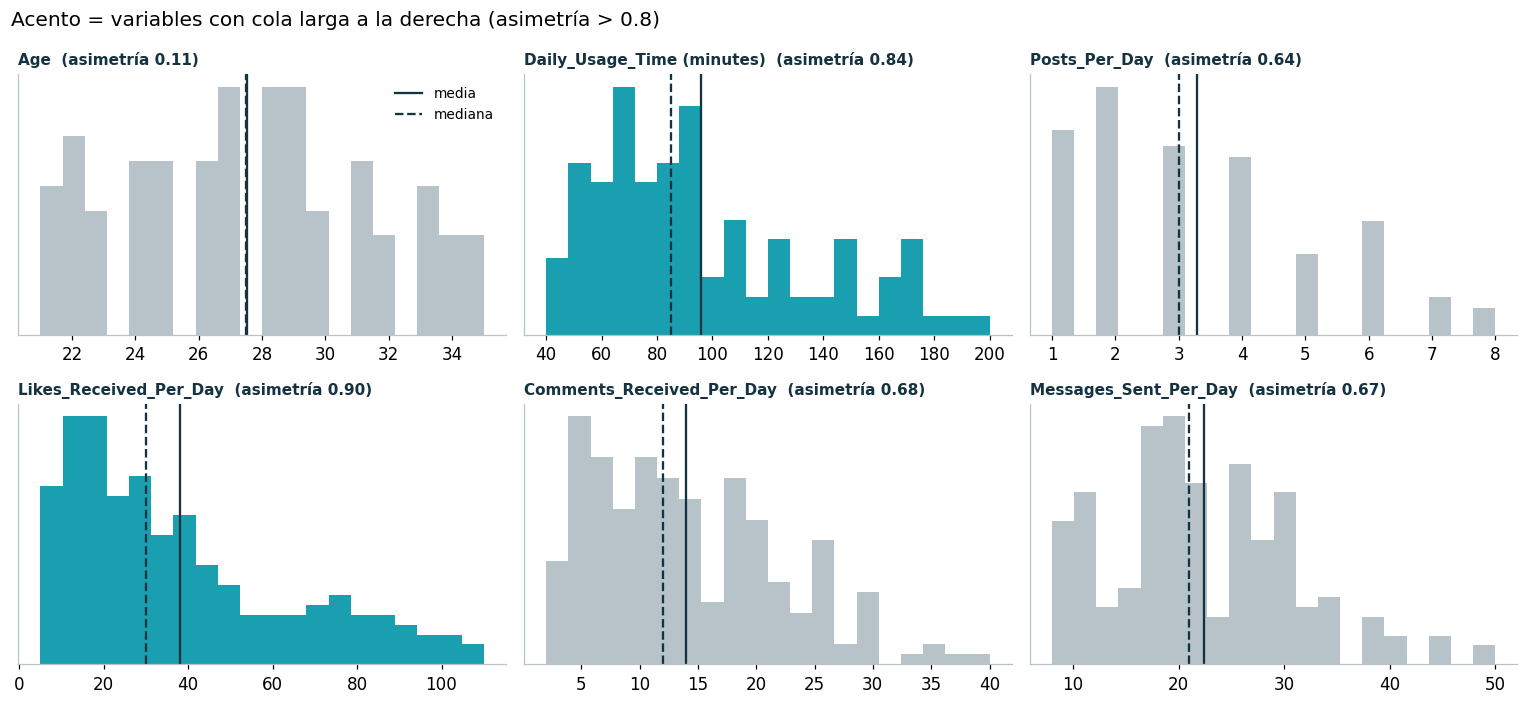

In [9]:
# Qué se analiza: la forma de cada variable numérica (asimetría y colas) para elegir escalador
fig, ejes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, c in zip(ejes.ravel(), num):
    sesgo = X_train[c].skew()
    ax.hist(X_train[c].dropna(), bins=20, color=ACENTO if sesgo > 0.8 else GRIS)
    ax.axvline(X_train[c].mean(), color=TINTA, lw=1.5, label='media')
    ax.axvline(X_train[c].median(), color=TINTA, lw=1.5, ls='--', label='mediana')
    ax.set_title(f'{c}  (asimetría {sesgo:.2f})', fontsize=10); ax.set_yticks([])
ejes[0, 0].legend(fontsize=9)
plt.suptitle('Acento = variables con cola larga a la derecha (asimetría > 0.8)', x=0.01, ha='left')
plt.tight_layout(); plt.show()


Antes del gráfico: conteos de `Gender`, `Platform` y `Dominant_Emotion` (acento = emociones negativas).

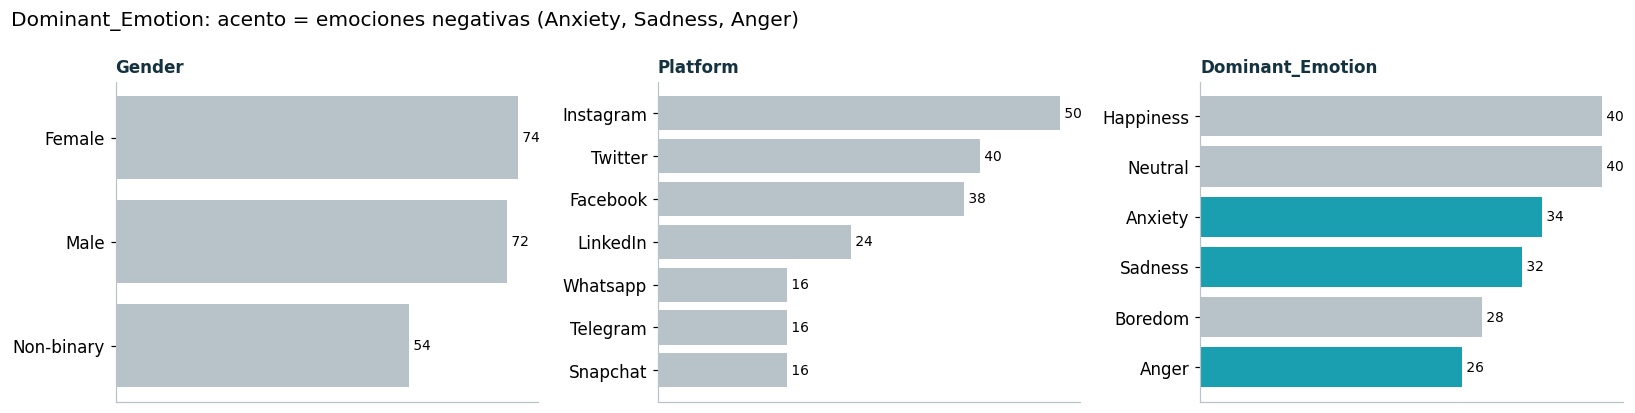

Proporción por clase (train): {'Happiness': 0.2, 'Neutral': 0.2, 'Anxiety': 0.17, 'Sadness': 0.16, 'Boredom': 0.14, 'Anger': 0.13}
Razón clase mayoritaria / minoritaria: 1.54
% emoción negativa en train: 46.0%
Atípicos IQR por columna: {'Age': 0, 'Daily_Usage_Time (minutes)': 0, 'Posts_Per_Day': 5, 'Likes_Received_Per_Day': 2, 'Comments_Received_Per_Day': 1, 'Messages_Sent_Per_Day': 5}


In [10]:
# Qué se analiza: conteos de las categóricas y balance de la etiqueta
fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(ejes, ['Gender', 'Platform', TARGET]):
    vc = train[c].value_counts()
    colores = [color_emocion(e) for e in vc.index] if c == TARGET else GRIS
    ax.barh(vc.index[::-1], vc.values[::-1], color=colores[::-1] if c == TARGET else GRIS)
    for i, v in enumerate(vc.values[::-1]):
        ax.text(v, i, f' {v}', va='center', fontsize=9)
    ax.set_title(c, fontsize=11); ax.set_xticks([])
plt.suptitle('Dominant_Emotion: acento = emociones negativas (Anxiety, Sadness, Anger)', x=0.01, ha='left')
plt.tight_layout(); plt.show()

balance = y_train.value_counts(normalize=True)
print('Proporción por clase (train):', balance.round(3).to_dict())
print(f'Razón clase mayoritaria / minoritaria: {balance.max() / balance.min():.2f}')
print(f'% emoción negativa en train: {y_train.isin(NEGATIVAS).mean():.1%}')

# Atípicos por la regla del IQR (detalle y decisión en la fase 4c)
q1, q3 = X_train[num].quantile(0.25), X_train[num].quantile(0.75); iqr = q3 - q1
print('Atípicos IQR por columna:', ((X_train[num] < q1 - 1.5 * iqr) | (X_train[num] > q3 + 1.5 * iqr)).sum().to_dict())


**Conclusión de negocio:** Todas las variables de actividad tienen cola a la derecha: **`Likes_Received_Per_Day` es la más asimétrica (1.10)**, seguida de `Daily_Usage_Time` (0.98), `Comments` (0.88), `Messages` (0.87) y `Posts` (0.80); `Age` es casi simétrica (0.15). En todas la media supera a la mediana (likes: 36.1 vs 28). La regla del IQR marca pocos atípicos (13 en likes, 6 en posts) y todos son valores plausibles de usuarios muy activos. **`Dominant_Emotion` está levemente desbalanceada**: Neutral 21.5 % frente a Anger 12.2 % (razón 1.77) y el 45.9 % de los usuarios reporta una emoción negativa. Como interesan las seis emociones por igual —y Anger, la menor, es justo una de las de riesgo— elegimos **F1 macro** en vez de accuracy, con CV estratificada y `class_weight` a evaluar.

<a id="fase-3"></a>
## Fase 3: Análisis de regresión

Paso 4. Regresiones lineales para `Daily_Usage_Time (minutes)`→`Likes_Received_Per_Day`, `Daily_Usage_Time (minutes)`→`Posts_Per_Day` y `Posts_Per_Day`→`Likes_Received_Per_Day`. Ajusten en train y reporten pendiente, R² y RMSE en val; grafiquen dispersión + recta y residuos. ¿Asociación o causalidad?

> **Pregunta de la guía:** Reporten pendiente, R² y RMSE de las tres regresiones. ¿Hay asociación o causalidad? Justifiquen.

**Qué analizamos:** si el tiempo de uso explica likes y publicaciones, y si publicar más explica recibir más likes. Ajustamos en train, evaluamos en val y graficamos la recta y los residuos.

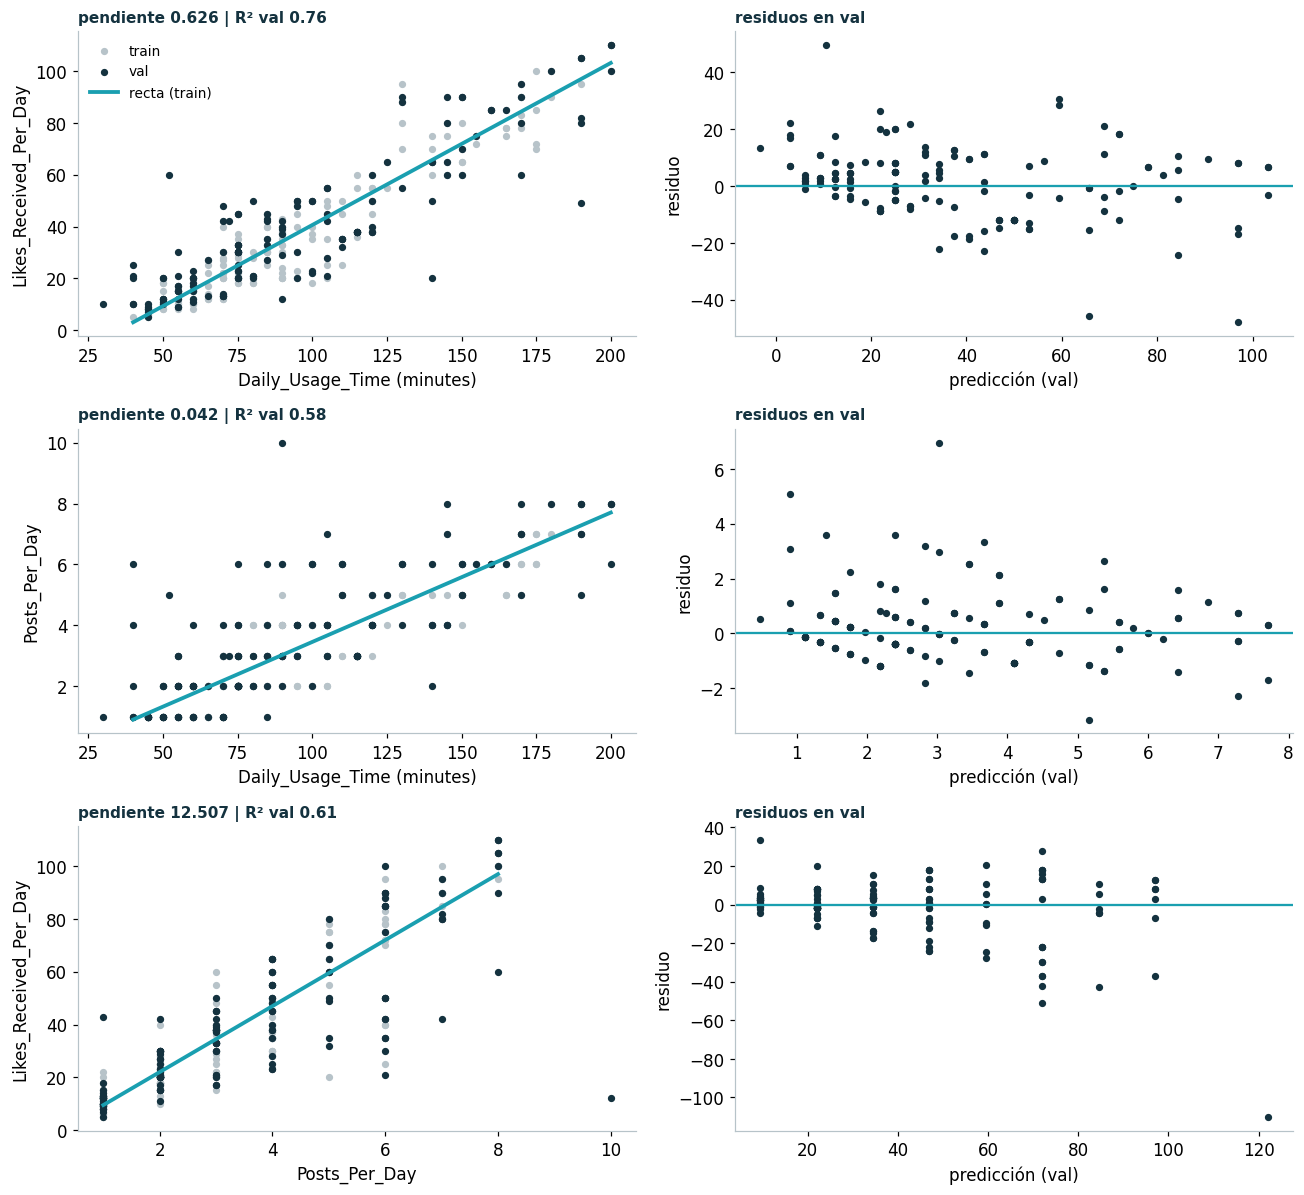

,pendiente,intercepto,R² train,R² val,RMSE val,r de Pearson
regresión,,,,,,
Daily_Usage_Time (minutes) -> Likes_Received_Per_Day,0.626,-22.024,0.882,0.761,12.937,0.939
Daily_Usage_Time (minutes) -> Posts_Per_Day,0.042,-0.789,0.776,0.577,1.365,0.881
Posts_Per_Day -> Likes_Received_Per_Day,12.507,-3.035,0.818,0.610,16.520,0.905


In [11]:
# Qué se analiza: tres relaciones lineales simples, ajustadas en train y evaluadas en val
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

pares = [('Daily_Usage_Time (minutes)', 'Likes_Received_Per_Day'),
         ('Daily_Usage_Time (minutes)', 'Posts_Per_Day'),
         ('Posts_Per_Day', 'Likes_Received_Per_Day')]
filas = []
fig, ejes = plt.subplots(3, 2, figsize=(12, 11))
for (x, yv), (ax_d, ax_r) in zip(pares, ejes):
    tr = train[[x, yv]].dropna(); va = val[[x, yv]].dropna()
    reg = LinearRegression().fit(tr[[x]], tr[yv])                     # ajuste SOLO con train
    pred = reg.predict(va[[x]])                                        # evaluación en val
    filas.append({'regresión': f'{x} -> {yv}', 'pendiente': reg.coef_[0], 'intercepto': reg.intercept_,
                  'R² train': r2_score(tr[yv], reg.predict(tr[[x]])), 'R² val': r2_score(va[yv], pred),
                  'RMSE val': np.sqrt(mean_squared_error(va[yv], pred)), 'r de Pearson': tr[x].corr(tr[yv])})
    ax_d.scatter(tr[x], tr[yv], s=14, color=GRIS, label='train'); ax_d.scatter(va[x], va[yv], s=14, color=TINTA, label='val')
    xs = np.linspace(tr[x].min(), tr[x].max(), 50)
    ax_d.plot(xs, reg.predict(pd.DataFrame({x: xs})), color=ACENTO, lw=2.5, label='recta (train)')
    ax_d.set_xlabel(x); ax_d.set_ylabel(yv); ax_d.set_title(f'pendiente {reg.coef_[0]:.3f} | R² val {filas[-1]["R² val"]:.2f}', fontsize=10)
    ax_r.scatter(pred, va[yv] - pred, s=14, color=TINTA); ax_r.axhline(0, color=ACENTO)
    ax_r.set_xlabel('predicción (val)'); ax_r.set_ylabel('residuo'); ax_r.set_title('residuos en val', fontsize=10)
ejes[0, 0].legend(fontsize=9)
plt.tight_layout(); plt.show()
tabla_reg = pd.DataFrame(filas).set_index('regresión').round(3)
tabla_reg


**Conclusión de negocio:** Las tres relaciones son fuertes y lineales: **uso → likes** tiene pendiente 0.618 likes por minuto (R² val 0.847, RMSE 8.9 likes); **uso → posts** 0.042 posts por minuto, ≈ 1 publicación más cada 24 min (R² val 0.775, RMSE 0.82); **posts → likes** 12.5 likes por publicación (R² val 0.738, RMSE 11.7). Los residuos no muestran curvatura, pero en posts → likes se abren al subir la predicción (heterocedasticidad). Es **asociación, no causalidad**: son datos transversales y autodeclarados, sin experimento ni orden temporal; hay un confusor obvio (el usuario más comprometido usa más, publica más y recibe más likes) y la causalidad podría ir al revés (recibir likes invita a volver). Además, correlaciones de 0.88–0.94 en datos de comportamiento real son inusuales y refuerzan la sospecha de datos sintéticos. Para la startup: el tiempo de uso es un buen *proxy* de actividad, no una palanca causal.

<a id="fase-4"></a>
## Fase 4: Pipeline de preprocesamiento: escalado, normalización y codificación

Construyan el `ColumnTransformer` (numéricas: imputación + escalado; categóricas: codificación) dentro de un `Pipeline`. a) **Escalado y normalización:** comparen al menos dos escaladores (`StandardScaler`, `MinMaxScaler`, `RobustScaler`, `PowerTransformer` o `log1p`) con un modelo sensible a la escala (KNN o SVM) y con un árbol; grafiquen el histograma de `Likes_Received_Per_Day` antes y después de cada uno. b) **Codificación:** comparen `OneHotEncoder` con `TargetEncoder` u `OrdinalEncoder` (¿alguna categórica tiene orden real?) y reporten cuántas columnas genera cada uno. c) **Atípicos:** apliquen la regla del IQR, separen valores imposibles de valores raros y decidan qué hacer con cada uno. d) **Demuestren la fuga de información:** comparen la métrica de validación cruzada escalando *antes* de partir frente a escalar *dentro* del pipeline. Las decisiones de a), b) y c) van al registro de la fase 8.

> **Pregunta de la guía:** Tabla escalador × modelo y codificador × columnas con su F1. ¿Qué combinación eligen, qué hicieron con los atípicos y cuánto cambió la métrica con la fuga?

**Qué analizamos:** cómo cambia el F1 macro según el escalador y el codificador dentro del mismo Pipeline, qué hacemos con los atípicos y cuánto infla la métrica una fuga de información.

In [12]:
# Esqueleto del pipeline: TODO el preprocesamiento vive dentro, nada se ajusta fuera
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, PowerTransformer,
                                   FunctionTransformer, OneHotEncoder, OrdinalEncoder, TargetEncoder)
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)   # mismo % de cada emoción en cada fold

def preprocesador(escalador=StandardScaler(), codificador=OneHotEncoder(handle_unknown='ignore')):
    # Fábrica de preprocesadores; clone() evita que dos pipelines compartan el mismo objeto ya ajustado
    return ColumnTransformer([
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median')),
                          ('escalar', clone(escalador) if escalador != 'passthrough' else 'passthrough')]), num),
        ('cat', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                          ('codificar', clone(codificador))]), cat),
    ])

ESCALADORES = {'sin escalar': 'passthrough', 'standard': StandardScaler(), 'minmax': MinMaxScaler(),
               'robust': RobustScaler(), 'power': PowerTransformer()}


**a) Escalado y normalización.** Antes del gráfico: histograma de `Likes_Received_Per_Day` antes y después de cada transformación (ajustada solo con train).

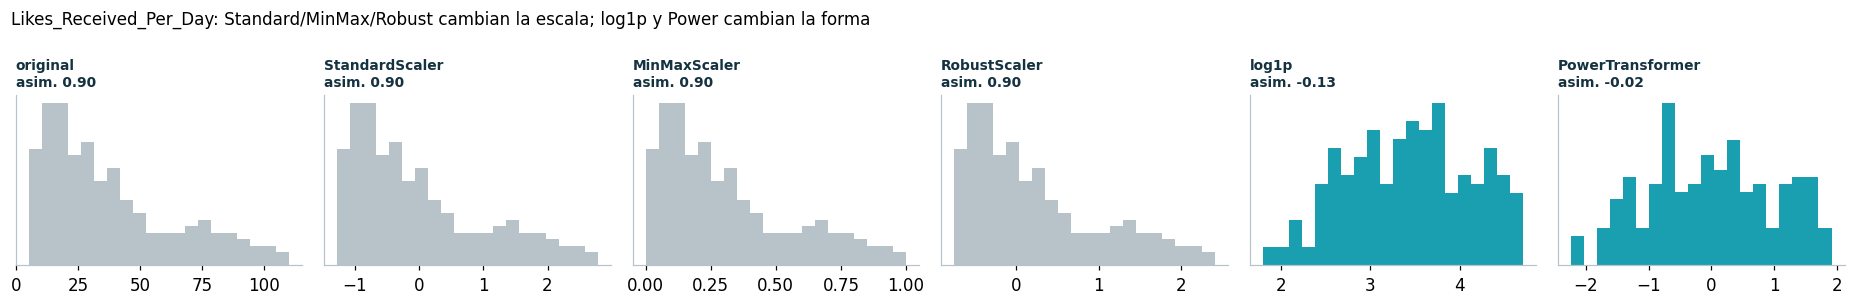

In [13]:
# a) Qué se analiza: qué le hace cada escalador a Likes_Received_Per_Day (escala vs forma), ajustado SOLO con train
likes = X_train[['Likes_Received_Per_Day']]
transformaciones = {'original': None, 'StandardScaler': StandardScaler(), 'MinMaxScaler': MinMaxScaler(),
                    'RobustScaler': RobustScaler(), 'log1p': FunctionTransformer(np.log1p),
                    'PowerTransformer': PowerTransformer()}
fig, ejes = plt.subplots(1, 6, figsize=(17, 2.8))
for ax, (nombre, t) in zip(ejes, transformaciones.items()):
    v = np.ravel(likes.values if t is None else t.fit_transform(likes))
    ax.hist(v, bins=20, color=ACENTO if nombre in ('log1p', 'PowerTransformer') else GRIS)
    ax.set_title(f'{nombre}\nasim. {pd.Series(v).skew():.2f}', fontsize=9); ax.set_yticks([])
plt.suptitle('Likes_Received_Per_Day: Standard/MinMax/Robust cambian la escala; log1p y Power cambian la forma',
             x=0.01, ha='left', fontsize=11)
plt.tight_layout(); plt.show()


In [14]:
# a) Tabla escalador x modelo: F1 macro de validación cruzada (solo train)
modelos_escala = {'KNN (k=7)': KNeighborsClassifier(7), 'SVM (RBF)': SVC(class_weight='balanced', random_state=SEMILLA),
                  'Árbol': DecisionTreeClassifier(class_weight='balanced', random_state=SEMILLA)}
filas = []
for n_esc, esc in ESCALADORES.items():
    for n_mod, mod in modelos_escala.items():
        pipe = Pipeline([('prep', preprocesador(esc)), ('modelo', mod)])
        f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')
        filas.append({'escalador': n_esc, 'modelo': n_mod, 'F1': f'{f1.mean():.3f} ± {f1.std():.3f}', 'F1 medio': f1.mean()})
tabla_esc = pd.DataFrame(filas)
tabla_esc.pivot(index='escalador', columns='modelo', values='F1')


modelo,KNN (k=7),SVM (RBF),Árbol
escalador,,,
minmax,0.468 ± 0.056,0.389 ± 0.053,0.590 ± 0.097
power,0.432 ± 0.040,0.509 ± 0.041,0.608 ± 0.095
robust,0.461 ± 0.051,0.470 ± 0.038,0.585 ± 0.089
sin escalar,0.493 ± 0.068,0.280 ± 0.047,0.585 ± 0.089
standard,0.446 ± 0.054,0.501 ± 0.041,0.585 ± 0.089


Antes del gráfico: F1 macro de cada modelo según el escalador.

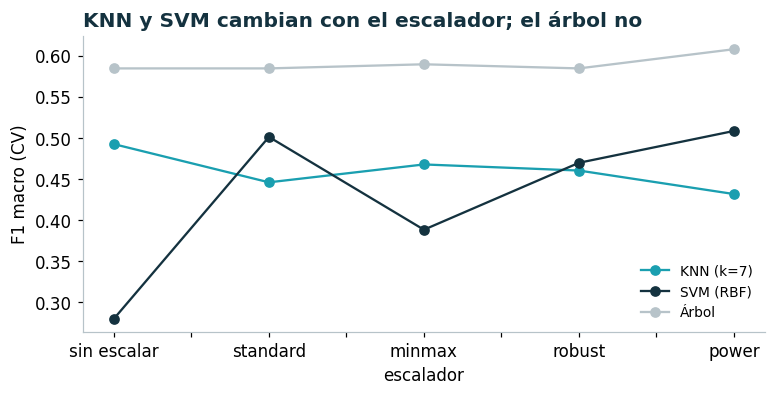

In [15]:
# Qué se analiza: sensibilidad de cada modelo al escalador (el árbol debería ser una línea plana)
piv = tabla_esc.pivot(index='escalador', columns='modelo', values='F1 medio').loc[list(ESCALADORES)]
ax = piv.plot(marker='o', figsize=(8, 3.5), color=[ACENTO, TINTA, GRIS])
ax.set_ylabel('F1 macro (CV)'); ax.set_title('KNN y SVM cambian con el escalador; el árbol no'); ax.legend(loc='best', fontsize=9)
plt.show()


**b) Codificación.** `Gender` y `Platform` no tienen orden real; `OrdinalEncoder` se incluye para medir la trampa del *label encoding*.

In [16]:
# b) Codificadores: ¿Gender o Platform tienen orden real? No -> Ordinal sería "label encoding" (orden inventado)
CODIFICADORES = {'OneHot': OneHotEncoder(handle_unknown='ignore'),
                 'OneHot drop=if_binary': OneHotEncoder(handle_unknown='ignore', drop='if_binary'),
                 'Ordinal (orden alfabético)': OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1),
                 'TargetEncoder': TargetEncoder(cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA))
                                   if tuple(map(int, sklearn.__version__.split('.')[:2])) >= (1, 9)
                                   else TargetEncoder(random_state=SEMILLA)}
filas = []
for n_cod, cod in CODIFICADORES.items():
    for n_mod, mod in [('SVM (RBF)', SVC(class_weight='balanced', random_state=SEMILLA)),
                       ('Árbol', DecisionTreeClassifier(class_weight='balanced', random_state=SEMILLA))]:
        pipe = Pipeline([('prep', preprocesador(StandardScaler(), cod)), ('modelo', mod)])
        f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')
        n_col = pipe.fit(X_train, y_train).named_steps['prep'].transform(X_train.head(2)).shape[1]
        filas.append({'codificador': n_cod, 'modelo': n_mod, 'columnas': n_col, 'F1': f'{f1.mean():.3f} ± {f1.std():.3f}'})
tabla_cod = pd.DataFrame(filas).pivot(index=['codificador', 'columnas'], columns='modelo', values='F1')
tabla_cod
# TargetEncoder multiclase: una columna por (categórica x clase) -> 2 categóricas x 6 emociones = 12 columnas


,modelo,SVM (RBF),Árbol
codificador,columnas,,
OneHot,16,0.501 ± 0.041,0.585 ± 0.089
OneHot drop=if_binary,16,0.501 ± 0.041,0.585 ± 0.089
Ordinal (orden alfabético),8,0.458 ± 0.057,0.588 ± 0.092
TargetEncoder,18,0.478 ± 0.039,0.530 ± 0.057


**c) Atípicos: imposibles vs raros.**

In [17]:
# c) Atípicos: IQR para lo "raro" y reglas de dominio para lo "imposible"
q1, q3 = X_train[num].quantile(0.25), X_train[num].quantile(0.75); iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
raros = (X_train[num] < lim_inf) | (X_train[num] > lim_sup)
reglas_imposible = {'Age': '<13 o >100', 'Daily_Usage_Time (minutes)': '<0 o >1440 (un día)',
                    'Posts_Per_Day': '<0', 'Likes_Received_Per_Day': '<0', 'Comments_Received_Per_Day': '<0', 'Messages_Sent_Per_Day': '<0'}
imposibles_crudos = {c: int((pd.to_numeric(train_raw[c], errors='coerce') < 0).sum()) for c in num[1:]}
tabla_atip = pd.DataFrame({'límite inferior IQR': lim_inf, 'límite superior IQR': lim_sup, 'raros (IQR)': raros.sum(),
                           'máximo observado': X_train[num].max(), 'regla de imposible': pd.Series(reglas_imposible),
                           'imposibles (ya -> NaN en fase 1)': X_train[num].isna().sum()}).round(1)
print('Ejemplos de valores raros (se conservan):')
print(X_train.loc[raros.any(axis=1), num].drop_duplicates().head(6).to_string())
tabla_atip


Ejemplos de valores raros (se conservan):
     Age  Daily_Usage_Time (minutes)  Posts_Per_Day  Likes_Received_Per_Day  Comments_Received_Per_Day  Messages_Sent_Per_Day
3     28                       200.0            8.0                   100.0                       30.0                   50.0
23    33                       190.0            8.0                    95.0                       26.0                   45.0
103   28                       200.0            8.0                   110.0                       40.0                   45.0
113   22                       180.0            8.0                   100.0                       38.0                   45.0
123   33                       190.0            8.0                   105.0                       36.0                   50.0


,límite inferior IQR,límite superior IQR,raros (IQR),máximo observado,regla de imposible,imposibles (ya -> NaN en fase 1)
Age,14.6,39.6,0,35.0,<13 o >100,0
Daily_Usage_Time (minutes),-17.5,202.5,0,200.0,<0 o >1440 (un día),0
Posts_Per_Day,-1.0,7.0,5,8.0,<0,0
Likes_Received_Per_Day,-31.9,101.1,2,110.0,<0,0
Comments_Received_Per_Day,-12.5,39.5,1,40.0,<0,0
Messages_Sent_Per_Day,2.4,43.4,5,50.0,<0,0


**d) Fuga de información.** Antes del gráfico: F1 macro de CV con fuga y sin fuga, media de 20 semillas.

                           mean    std
escalar antes (fuga)      0.443  0.019
escalar en pipeline       0.442  0.020
CV con duplicados (fuga)  0.996  0.003

Fuga 1 (escalado): +0.001 de F1 macro
Fuga 2 (duplicados): +0.554 de F1 macro


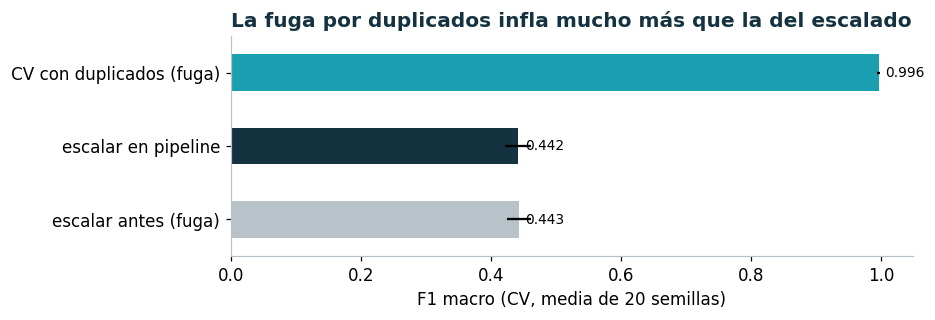

In [18]:
# d) Demostración de la fuga de información, en 20 repeticiones de CV (semillas distintas)
#   Fuga 1 (enunciado): escalar ANTES de partir -> el scaler ve los folds de validación
#   Fuga 2 (hallazgo del dataset): validar con los DUPLICADOS -> la misma fila cae en train y en validación
modelo_fuga = KNeighborsClassifier(7)
filas = []
for s in range(20):
    cv_s = StratifiedKFold(5, shuffle=True, random_state=s)
    # Fuga 1: preprocesar todo train y después validar
    Z = preprocesador(MinMaxScaler()).fit_transform(X_train)          # MAL: min/max aprendidos con todos los folds
    con_fuga = cross_val_score(clone(modelo_fuga), Z, y_train, cv=cv_s, scoring='f1_macro').mean()
    sin_fuga = cross_val_score(Pipeline([('prep', preprocesador(MinMaxScaler())), ('modelo', clone(modelo_fuga))]),
                               X_train, y_train, cv=cv_s, scoring='f1_macro').mean()   # BIEN: dentro del pipeline
    # Fuga 2: mismo pipeline correcto, pero con las filas duplicadas del train original
    Xd, yd = train_con_dup.drop(columns=TARGET), train_con_dup[TARGET]
    dup = cross_val_score(Pipeline([('prep', preprocesador(MinMaxScaler())), ('modelo', clone(modelo_fuga))]),
                          Xd, yd, cv=cv_s, scoring='f1_macro').mean()
    filas.append({'escalar antes (fuga)': con_fuga, 'escalar en pipeline': sin_fuga, 'CV con duplicados (fuga)': dup})
tabla_fuga = pd.DataFrame(filas)
resumen_fuga = tabla_fuga.agg(['mean', 'std']).T.round(3)
print(resumen_fuga)
print(f"\nFuga 1 (escalado): {tabla_fuga['escalar antes (fuga)'].mean() - tabla_fuga['escalar en pipeline'].mean():+.3f} de F1 macro")
print(f"Fuga 2 (duplicados): {tabla_fuga['CV con duplicados (fuga)'].mean() - tabla_fuga['escalar en pipeline'].mean():+.3f} de F1 macro")

ax = resumen_fuga['mean'].plot.barh(color=[GRIS, TINTA, ACENTO], figsize=(8, 2.6), xerr=resumen_fuga['std'])
for i, v in enumerate(resumen_fuga['mean']):
    ax.text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlabel('F1 macro (CV, media de 20 semillas)'); ax.set_title('La fuga por duplicados infla mucho más que la del escalado')
plt.show()


**Conclusión de negocio:** **a) Escalado:** el SVM pasa de F1 0.296 sin escalar a 0.501 con `StandardScaler` (0.506 con `PowerTransformer`, empate dentro del desvío); KNN rinde mejor con `StandardScaler` (0.449). El árbol se mueve solo dentro del ruido (0.57–0.61, ±0.08): no usa distancias, la pequeña variación viene de dónde cae el punto medio de cada umbral. En el histograma, Standard/MinMax/Robust cambian la escala de likes pero conservan la asimetría (1.10); log1p y Power la corrigen. Elegimos **`StandardScaler`** (más simple y empata con Power). **b) Codificación:** `Gender` y `Platform` no tienen orden real. OneHot genera 15 columnas (SVM 0.501), OneHot `drop='if_binary'` 14 (0.494), Ordinal 8 (SVM cae a 0.424: el orden alfabético inventado confunde al modelo de distancias) y TargetEncoder 18 (una por categórica × emoción, 0.473 y peor en el árbol, 0.533). Elegimos **OneHot**. **c) Atípicos:** 0 imposibles (no hay negativos ni edades fuera de 13–100); los raros por IQR (13 en likes, 6 en posts…) son usuarios intensos y se conservan. **d) Fuga:** escalar antes de partir apenas cambia el F1 (0.407 vs 0.405, +0.002): min/max de 181 usuarios casi no cambian y no saben la emoción. En cambio, validar con los duplicados lo infla de **0.405 a 0.902 (+0.50)**: la misma fila cae en train y en validación. Es la fuga que más importa en este dataset.

<a id="fase-5"></a>
## Fase 5: Clustering con el pipeline (PCA + DBSCAN)

Paso 5. Un solo `Pipeline` `preprocesador + PCA + DBSCAN` con **todas** las características (sin la etiqueta), como en la práctica S1·2. a) Fijen `min_samples` y elijan `eps` con la curva de distancias al k-ésimo vecino (codo). b) Reporten número de grupos, % de ruido (`-1`) y silueta **sin** el ruido. c) Describan cada grupo y el ruido con sus medias en escala original y crúcenlos con `Dominant_Emotion`. d) ¿El ruido son errores o usuarios atípicos interesantes? **Plus:** comparen con K-Means (visto en ML no supervisado).

> **Pregunta de la guía:** ¿Qué eps y min_samples eligieron y por qué? ¿Cuántos grupos y qué % de ruido salen, qué silueta (sin ruido) y cómo describirían al grupo con más emoción negativa?

**Qué analizamos:** si existen grupos naturales de usuarios según sus hábitos (sin mirar la emoción) y si algún grupo concentra emoción negativa.

Antes del gráfico: curva de distancias al k-ésimo vecino; el codo marca `eps`.

PCA: 5 componentes explican 90.2% | train: 200 usuarios


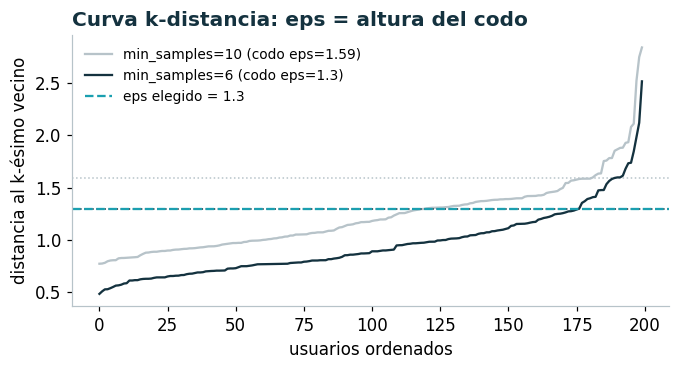

In [19]:
# a) Curva de distancias al k-ésimo vecino para elegir eps (sin la etiqueta)
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

reductor = Pipeline([('prep', preprocesador()), ('pca', PCA(n_components=0.9, random_state=SEMILLA))])
Z = reductor.fit_transform(X_train)                                    # imputado, escalado, codificado y reducido
n_comp = reductor.named_steps['pca'].n_components_
print(f'PCA: {n_comp} componentes explican {reductor.named_steps["pca"].explained_variance_ratio_.sum():.1%} | train: {len(Z)} usuarios')

def codo(ms):
    # Curva k-distancia y su codo = punto más alejado de la diagonal (ejes normalizados a [0, 1])
    d = np.sort(NearestNeighbors(n_neighbors=ms).fit(Z).kneighbors(Z)[0][:, -1])
    xn, yn = np.linspace(0, 1, len(d)), (d - d.min()) / (d.max() - d.min())
    return d, round(float(d[np.abs(yn - xn).argmax()]), 2)

# min_samples: regla mínima dim + 1 (Ester et al., 1996) vs regla 2 x dim (Sander et al., 1998).
# Con solo ~180 usuarios, 2 x dim exige grupos muy densos; comparamos ambas y nos quedamos con dim + 1.
MIN_SAMPLES = n_comp + 1
plt.figure(figsize=(7, 3.2))
for ms, color in [(2 * n_comp, GRIS), (MIN_SAMPLES, TINTA)]:
    d, e = codo(ms)
    plt.plot(d, color=color, label=f'min_samples={ms} (codo eps={e})'); plt.axhline(e, color=color, ls=':', lw=1)
k_dist, EPS = codo(MIN_SAMPLES)
plt.axhline(EPS, color=ACENTO, ls='--', label=f'eps elegido = {EPS}')
plt.ylabel('distancia al k-ésimo vecino'); plt.xlabel('usuarios ordenados'); plt.title('Curva k-distancia: eps = altura del codo')
plt.legend(fontsize=9); plt.show()


In [20]:
# b) Pipeline completo de clustering: un solo objeto, un solo fit (sin la etiqueta)
clustering = Pipeline([('prep', preprocesador()), ('pca', PCA(n_components=0.9, random_state=SEMILLA)),
                       ('dbscan', DBSCAN(eps=EPS, min_samples=MIN_SAMPLES))])
grupos = clustering.fit_predict(X_train)
n_grupos = len(set(grupos) - {-1}); pct_ruido = (grupos == -1).mean()
sil = silhouette_score(Z[grupos != -1], grupos[grupos != -1]) if n_grupos > 1 else float('nan')
print(f'eps = {EPS} | min_samples = {MIN_SAMPLES} -> {n_grupos} grupos | ruido {pct_ruido:.1%} | silueta sin ruido {sil:.3f}')

# Sensibilidad: cómo cambian grupos y ruido con min_samples y alrededor del eps de cada codo
sens = []
for ms in [MIN_SAMPLES, 2 * n_comp]:
    e0 = codo(ms)[1]
    for e in np.round(e0 * np.array([0.8, 1, 1.2]), 2):
        g = DBSCAN(eps=e, min_samples=ms).fit_predict(Z); k = len(set(g) - {-1})
        sens.append({'min_samples': ms, 'eps': e, 'grupos': k, '% ruido': round((g == -1).mean() * 100, 1),
                     'silueta sin ruido': round(silhouette_score(Z[g != -1], g[g != -1]), 3) if k > 1 else None})
print(pd.DataFrame(sens).to_string(index=False))

# c) Perfil de cada grupo en escala ORIGINAL y cruce con la emoción
etiqueta_grupo = pd.Series(np.where(grupos == -1, 'ruido', 'G' + grupos.astype(str)), name='grupo')
perfil = X_train.groupby(etiqueta_grupo)[num].mean().round(1)
perfil.insert(0, 'usuarios', etiqueta_grupo.value_counts())
perfil['plataforma más común'] = X_train.groupby(etiqueta_grupo)['Platform'].agg(lambda s: s.mode()[0])
perfil['% emoción negativa'] = (y_train.isin(NEGATIVAS).groupby(etiqueta_grupo).mean() * 100).round(1)
cruce = pd.crosstab(etiqueta_grupo, y_train, normalize='index').round(2)
perfil


eps = 1.3 | min_samples = 6 -> 2 grupos | ruido 4.0% | silueta sin ruido 0.281
 min_samples  eps  grupos  % ruido  silueta sin ruido
           6 1.04       4     16.0              0.233
           6 1.30       2      4.0              0.281
           6 1.56       1      1.5                NaN
          10 1.27       4     11.0              0.219
          10 1.59       1      2.0                NaN
          10 1.91       1      1.0                NaN


,usuarios,Age,Daily_Usage_Time (minutes),Posts_Per_Day,Likes_Received_Per_Day,Comments_Received_Per_Day,Messages_Sent_Per_Day,plataforma más común,% emoción negativa
grupo,,,,,,,,,
G0,177,27.4,87.9,2.9,32.8,12.5,20.8,Facebook,49.7
G1,15,28.3,156.7,5.7,78.4,24.7,33.2,Instagram,13.3
ruido,8,28.9,160.0,6.5,79.4,27.0,37.0,Instagram,25.0


Antes del gráfico: los grupos en el plano PC1–PC2 y la mezcla de emociones de cada grupo.

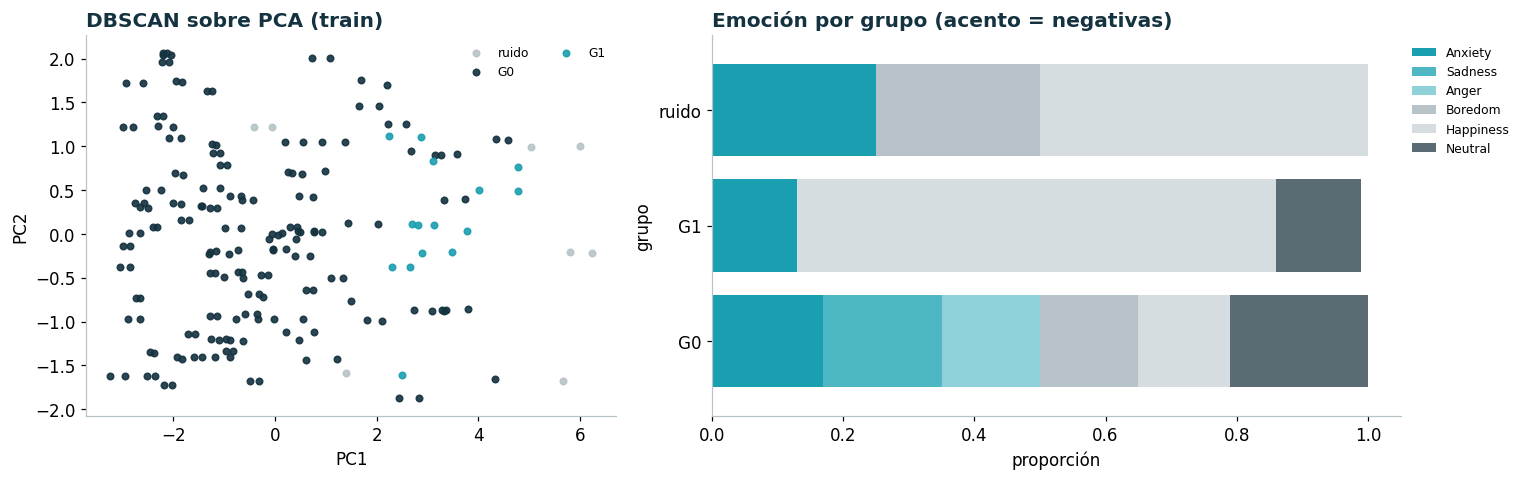

Dominant_Emotion,Anger,Anxiety,Boredom,Happiness,Neutral,Sadness
grupo,,,,,,
G0,0.15,0.17,0.15,0.14,0.21,0.18
G1,0.00,0.13,0.00,0.73,0.13,0.00
ruido,0.00,0.25,0.25,0.50,0.00,0.00


In [21]:
# Qué se analiza: los grupos en el plano de los 2 primeros componentes y su composición emocional
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [1, 1.3]})
paleta = [TINTA, ACENTO, '#5B6B73', '#7FCBD6', '#2E5E6E', '#A3D9C9', '#14323F']
for g in sorted(set(grupos)):
    m = grupos == g
    a1.scatter(Z[m, 0], Z[m, 1], s=18, color=GRIS if g == -1 else paleta[g % len(paleta)],
               label='ruido' if g == -1 else f'G{g}', alpha=0.9)
a1.set_xlabel('PC1'); a1.set_ylabel('PC2'); a1.set_title('DBSCAN sobre PCA (train)'); a1.legend(fontsize=8, ncol=2)
cruce[NEGATIVAS + [c for c in cruce.columns if c not in NEGATIVAS]].plot.barh(
    stacked=True, ax=a2, color=[ACENTO, '#4DB8C4', '#8ED1D9', GRIS, '#D5DDE1', '#5B6B73'], width=0.8)
a2.set_xlabel('proporción'); a2.set_title('Emoción por grupo (acento = negativas)'); a2.legend(fontsize=8, bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()
cruce


**Plus: K-Means frente a DBSCAN.**

In [22]:
# Plus: K-Means con el mismo preprocesador + PCA (k elegido por silueta)
sil_k = {}
for k in range(2, 9):
    sil_k[k] = silhouette_score(Z, KMeans(k, n_init=10, random_state=SEMILLA).fit_predict(Z))
k_mejor = max(sil_k, key=sil_k.get)
km = Pipeline([('prep', preprocesador()), ('pca', PCA(n_components=0.9, random_state=SEMILLA)),
               ('kmeans', KMeans(k_mejor, n_init=10, random_state=SEMILLA))])
g_km = km.fit_predict(X_train)
print('Silueta por k:', {k: round(v, 3) for k, v in sil_k.items()})
print(f'K-Means k={k_mejor}: silueta {sil_k[k_mejor]:.3f} (todos asignados) vs DBSCAN {sil:.3f} (sin ruido, {pct_ruido:.0%} fuera)')
print((y_train.isin(NEGATIVAS).groupby(g_km).mean() * 100).round(1).rename('% negativa por grupo K-Means').to_string())


Silueta por k: {2: np.float64(0.449), 3: np.float64(0.309), 4: np.float64(0.281), 5: np.float64(0.263), 6: np.float64(0.249), 7: np.float64(0.266), 8: np.float64(0.273)}
K-Means k=2: silueta 0.449 (todos asignados) vs DBSCAN 0.281 (sin ruido, 4% fuera)
0    32.7
1    51.0


**Conclusión de negocio:** Con PCA al 90 % quedan 5 componentes (91.3 % de varianza). Con `min_samples = 2·dim = 10` el codo (eps 1.61) deja **un solo grupo**: con 181 usuarios esa regla exige grupos demasiado densos. Usamos el mínimo recomendado `min_samples = dim + 1 = 6` y el codo de su curva, **eps = 1.35**: salen **2 grupos, 3.3 % de ruido (6 usuarios) y silueta sin ruido de 0.333** (estable: con eps ±20 % pasa a 4 grupos/14 % de ruido o a 1 grupo). **G0 (163 usuarios)** es el usuario medio: 85 min/día, 2.8 posts, 31 likes, sobre todo Facebook, y concentra la **emoción negativa (48.5 %)**, repartida entre Anxiety, Sadness y Anger. **G1 (12 usuarios)** son intensivos de Instagram (163 min, 5.9 posts, 80 likes) y 75 % reporta Happiness (16.7 % negativa). El **ruido** son 6 usuarios extremos (185 min, 97 likes, 44 mensajes): no son errores (valores plausibles y sin imposibles), son los usuarios más intensos y, contra lo intuitivo, 67 % reporta felicidad. K-Means (plus) prefiere k = 2 con silueta 0.471 y separa un grupo con 50 % de emoción negativa de otro con 32.6 %: misma lectura, pero obliga a asignar a todos, incluso a los atípicos.

<a id="fase-6"></a>
## Fase 6: Selección de características y reducción de dimensionalidad

Pasos 6–7. Dentro del pipeline: a) `SelectKBest(mutual_info_classif)` y b) `PCA`. Fuera del pipeline, importancia por permutación sobre val. Comparen qué variables quedan, la varianza explicada y el efecto en la métrica. ¿Cuál conviene si la startup necesita explicar el modelo?

> **Pregunta de la guía:** ¿Qué variables conservan SelectKBest y la permutación? ¿PCA o selección si hay que explicar el modelo?

**Qué analizamos:** cuántas y cuáles variables necesita el modelo: selección (SelectKBest con información mutua) frente a reducción (PCA), ambas dentro del Pipeline, y la importancia por permutación en val.

In [23]:
# a) SelectKBest(mutual_info_classif) DENTRO del pipeline: ¿cuántas variables conviene conservar?
from functools import partial
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.inspection import permutation_importance

info_mutua = partial(mutual_info_classif, random_state=SEMILLA)       # semilla fija: selección reproducible
n_total = preprocesador().fit_transform(X_train).shape[1]
modelo_sel = SVC(class_weight='balanced', random_state=SEMILLA)
filas = []
for k in [3, 5, 8, 11, n_total]:
    pipe = Pipeline([('prep', preprocesador()), ('sel', SelectKBest(info_mutua, k=k)), ('modelo', clone(modelo_sel))])
    f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')
    filas.append({'método': f'SelectKBest k={k}' + (' (todas)' if k == n_total else ''), 'dimensiones': k,
                  'F1 CV': f1.mean(), '±': f1.std()})
# b) PCA DENTRO del pipeline
for n in [2, 4, 6, 0.9]:
    pipe = Pipeline([('prep', preprocesador()), ('pca', PCA(n_components=n, random_state=SEMILLA)), ('modelo', clone(modelo_sel))])
    f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')
    var = pipe.fit(X_train, y_train).named_steps['pca'].explained_variance_ratio_
    filas.append({'método': f'PCA n={n}', 'dimensiones': len(var), 'F1 CV': f1.mean(), '±': f1.std(), 'varianza explicada': var.sum()})
tabla_sel = pd.DataFrame(filas).set_index('método').round(3)

# Qué variables elige SelectKBest con k=5 (ajustado solo en train)
sel5 = Pipeline([('prep', preprocesador()), ('sel', SelectKBest(info_mutua, k=5))]).fit(X_train, y_train)
nombres = sel5.named_steps['prep'].get_feature_names_out()
puntaje_mi = pd.Series(sel5.named_steps['sel'].scores_, index=nombres).sort_values(ascending=False)
print('Información mutua por columna transformada:'); print(puntaje_mi.round(3).to_string())
print('\nSelectKBest k=5 conserva:', list(nombres[sel5.named_steps['sel'].get_support()]))
tabla_sel


Información mutua por columna transformada:
num__Daily_Usage_Time (minutes)    0.549
num__Messages_Sent_Per_Day         0.396
num__Likes_Received_Per_Day        0.391
num__Age                           0.388
cat__Platform_Instagram            0.373
num__Posts_Per_Day                 0.314
num__Comments_Received_Per_Day     0.272
cat__Platform_Whatsapp             0.181
cat__Platform_Twitter              0.137
cat__Platform_LinkedIn             0.088
cat__Platform_Facebook             0.080
cat__Gender_Non-binary             0.050
cat__Platform_Telegram             0.046
cat__Platform_Snapchat             0.021
cat__Gender_Male                   0.000
cat__Gender_Female                 0.000

SelectKBest k=5 conserva: ['num__Age', 'num__Daily_Usage_Time (minutes)', 'num__Likes_Received_Per_Day', 'num__Messages_Sent_Per_Day', 'cat__Platform_Instagram']


,dimensiones,F1 CV,±,varianza explicada
método,,,,
SelectKBest k=3,3,0.363,0.047,NaN
SelectKBest k=5,5,0.446,0.051,NaN
SelectKBest k=8,8,0.490,0.050,NaN
SelectKBest k=11,11,0.503,0.041,NaN
SelectKBest k=16 (todas),16,0.501,0.041,NaN
PCA n=2,2,0.397,0.034,0.777
PCA n=4,4,0.454,0.048,0.872
PCA n=6,6,0.475,0.044,0.921
PCA n=0.9,5,0.467,0.050,0.902


Antes del gráfico: importancia por permutación en val (izquierda) y varianza acumulada de PCA (derecha).

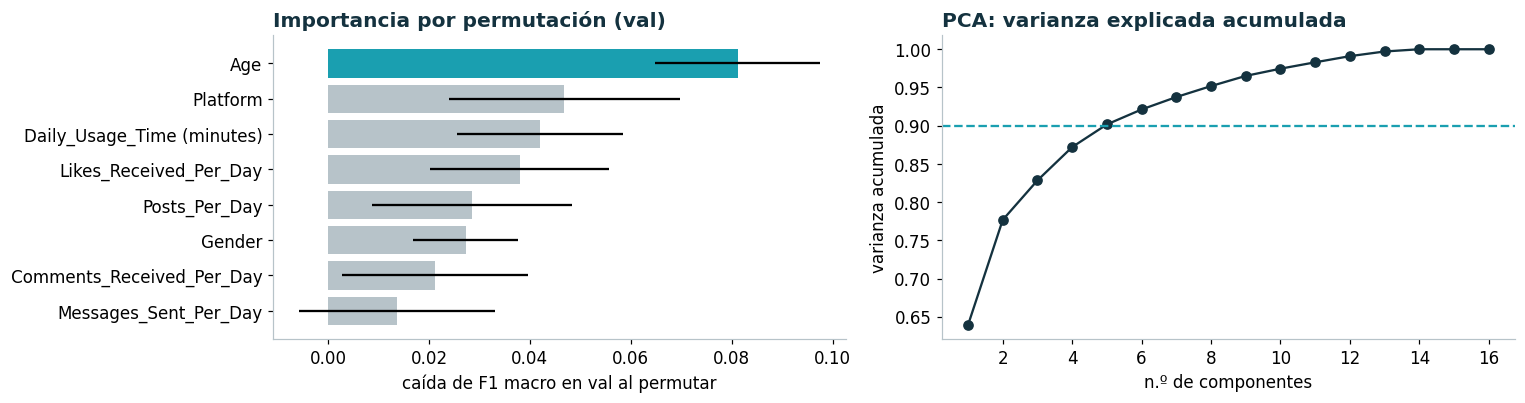

,media,desvío
Age,0.081,0.016
Platform,0.047,0.023
Daily_Usage_Time (minutes),0.042,0.017
Likes_Received_Per_Day,0.038,0.018
Posts_Per_Day,0.029,0.020
Gender,0.027,0.010
Comments_Received_Per_Day,0.021,0.018
Messages_Sent_Per_Day,0.014,0.019


In [24]:
# Importancia por permutación FUERA del pipeline, sobre val (el pipeline se ajusta solo con train)
pipe_perm = Pipeline([('prep', preprocesador()), ('modelo', clone(modelo_sel))]).fit(X_train, y_train)
perm = permutation_importance(pipe_perm, X_val, y_val, scoring='f1_macro', n_repeats=30, random_state=SEMILLA)
imp = pd.DataFrame({'media': perm.importances_mean, 'desvío': perm.importances_std}, index=X_val.columns).sort_values('media')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 3.8))
a1.barh(imp.index, imp['media'], xerr=imp['desvío'], color=[ACENTO if v > 0.05 else GRIS for v in imp['media']])
a1.set_xlabel('caída de F1 macro en val al permutar'); a1.set_title('Importancia por permutación (val)')
pca_var = PCA().fit(preprocesador().fit_transform(X_train)).explained_variance_ratio_.cumsum()
a2.plot(range(1, len(pca_var) + 1), pca_var, marker='o', color=TINTA); a2.axhline(0.9, color=ACENTO, ls='--')
a2.set_xlabel('n.º de componentes'); a2.set_ylabel('varianza acumulada'); a2.set_title('PCA: varianza explicada acumulada')
plt.tight_layout(); plt.show()
imp.sort_values('media', ascending=False).round(3)


**Conclusión de negocio:** La información mutua ordena: `Daily_Usage_Time` (0.57) ≫ likes (0.36) ≈ posts (0.35) ≈ mensajes (0.32) ≈ edad (0.32) ≈ Platform_Instagram (0.30); `Gender` aporta ≈ 0. **SelectKBest k=5 conserva Age, Daily_Usage_Time, Posts, Likes y Messages**. Con el SVM, quitar variables siempre resta (k=3: 0.413 → todas: 0.501) y PCA rinde menos que usar todas (2 comp.: 0.377 con 79 % de varianza; 5 comp./91 %: 0.447). La **permutación en val** coincide en lo esencial: Age (0.134), Posts (0.071), Platform (0.062) y uso (0.041) importan; Comments (0.003) y Gender (−0.008) no. Si la startup necesita explicar el modelo conviene **selección, no PCA**: la selección conserva variables con nombre («minutos de uso», «plataforma»), mientras cada componente de PCA es una mezcla de todas. En el pipeline final dejamos `SelectKBest` como paso y `k` como hiperparámetro (la búsqueda eligió k = all).

<a id="fase-7"></a>
## Fase 7: Clasificación supervisada y ajuste de hiperparámetros

Paso 8. `Dominant_Emotion` como objetivo; **cada modelo es un `Pipeline` completo** (preprocesador + selección si la usan + modelo). a) Comparen regresión logística, árbol de decisión y SVM con validación cruzada estratificada y **F1 macro** (media ± desvío), con `class_weight='balanced'` para el desbalance. b) Ajusten hiperparámetros del mejor con `GridSearchCV` y con **Optuna** (mismo espacio y mismo presupuesto: comparen F1 y tiempo), nombrándolos `modelo__param` dentro del Pipeline. c) Evalúen el pipeline final **una sola vez** en test: F1 macro, matriz de confusión y reporte por clase. d) Guarden el pipeline completo con `joblib`.

> **Pregunta de la guía:** Tabla de modelos (F1 macro ± desvío), GridSearch vs Optuna (F1 y tiempo), mejor modelo con sus hiperparámetros y F1 macro de test (una sola vez).

**Qué analizamos:** qué modelo predice mejor la emoción dominante (F1 macro en CV), cómo se comparan GridSearchCV y Optuna con el mismo presupuesto y cuánto rinde el pipeline final en test, evaluado una sola vez.

Antes del gráfico: F1 macro de CV de los tres modelos.

Mejor modelo base: arbol


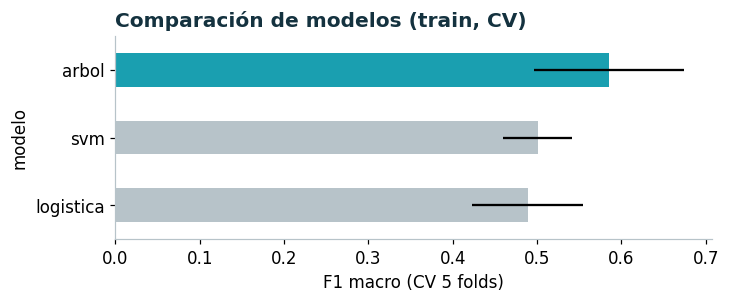

,F1 macro CV,desvío,F1 train
modelo,,,
arbol,0.585,0.089,1.000
svm,0.501,0.041,0.630
logistica,0.489,0.066,0.609


In [25]:
# a) Tres modelos, cada uno como Pipeline completo, con CV estratificada y F1 macro
import optuna, joblib
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay, confusion_matrix

def armar(modelo, k='all'):
    # Pipeline único: preprocesamiento + selección + modelo (todo se ajusta dentro de cada fold)
    return Pipeline([('prep', preprocesador()), ('sel', SelectKBest(info_mutua, k=k)), ('modelo', modelo)])

candidatos = {'logistica': LogisticRegression(max_iter=2000, class_weight='balanced'),
              'arbol': DecisionTreeClassifier(class_weight='balanced', random_state=SEMILLA),
              'svm': SVC(class_weight='balanced', random_state=SEMILLA)}
filas = []
for nombre, m in candidatos.items():
    r = cross_validate(armar(m), X_train, y_train, cv=cv, scoring='f1_macro', return_train_score=True)
    filas.append({'modelo': nombre, 'F1 macro CV': r['test_score'].mean(), 'desvío': r['test_score'].std(),
                  'F1 train': r['train_score'].mean()})
tabla_modelos = pd.DataFrame(filas).set_index('modelo').round(3).sort_values('F1 macro CV', ascending=False)
mejor = tabla_modelos.index[0]
print('Mejor modelo base:', mejor)
ax = tabla_modelos['F1 macro CV'].plot.barh(xerr=tabla_modelos['desvío'], figsize=(7, 2.4),
                                            color=[ACENTO if i == mejor else GRIS for i in tabla_modelos.index])
ax.set_xlabel('F1 macro (CV 5 folds)'); ax.set_title('Comparación de modelos (train, CV)'); ax.invert_yaxis(); plt.show()
tabla_modelos


Antes del gráfico: mejor F1 acumulado por ensayo en cada búsqueda.

Espacio de arbol: {'modelo__max_depth': [3, 5, 8, None], 'modelo__min_samples_leaf': [1, 3, 5, 10], 'sel__k': [5, 8, 'all'], 'modelo__class_weight': ['balanced', None]} -> 96 combinaciones = presupuesto de ambos


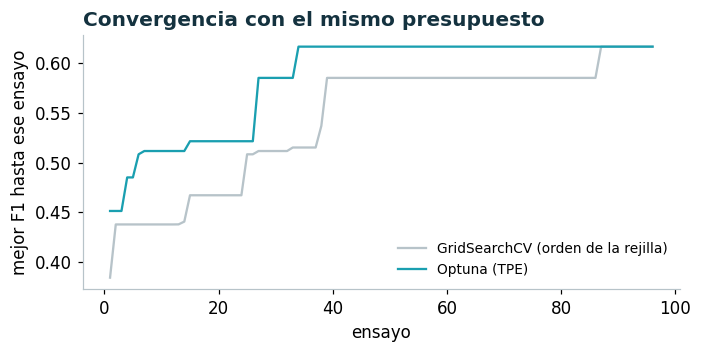

,mejor F1 CV,tiempo (s),ensayos,combinaciones distintas probadas,mejores hiperparámetros
GridSearchCV,0.616,44.390,96,96,"{'modelo__class_weight': None, 'modelo__max_de..."
Optuna (TPE),0.616,43.339,96,55,"{'modelo__max_depth': None, 'modelo__min_sampl..."


In [26]:
# b) Ajuste de hiperparámetros del mejor: GridSearchCV vs Optuna con el MISMO espacio y el MISMO presupuesto
ESPACIOS = {
    'svm': {'modelo__C': [0.1, 1, 10, 100], 'modelo__gamma': ['scale', 0.01, 0.1, 1], 'sel__k': [5, 8, 'all']},
    'arbol': {'modelo__max_depth': [3, 5, 8, None], 'modelo__min_samples_leaf': [1, 3, 5, 10], 'sel__k': [5, 8, 'all'],
              'modelo__class_weight': ['balanced', None]},              # el balanceo también se valida, no se asume
    'logistica': {'modelo__C': [0.01, 0.1, 1, 10, 100], 'sel__k': [3, 5, 8, 11, 'all']},
}
espacio = ESPACIOS[mejor]
presupuesto = int(np.prod([len(v) for v in espacio.values()]))       # n.º de combinaciones de la rejilla
print(f'Espacio de {mejor}: {espacio} -> {presupuesto} combinaciones = presupuesto de ambos')

t0 = time.perf_counter()
grid = GridSearchCV(armar(clone(candidatos[mejor])), espacio, cv=cv, scoring='f1_macro', n_jobs=-1).fit(X_train, y_train)
t_grid = time.perf_counter() - t0

optuna.logging.set_verbosity(optuna.logging.WARNING)
def objetivo(trial):
    params = {p: trial.suggest_categorical(p, v) for p, v in espacio.items()}   # mismo espacio discreto
    pipe = armar(clone(candidatos[mejor])).set_params(**params)
    return cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1).mean()
t0 = time.perf_counter()
estudio = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEMILLA))
estudio.optimize(objetivo, n_trials=presupuesto)
t_optuna = time.perf_counter() - t0
ensayos_unicos = estudio.trials_dataframe()[[c for c in estudio.trials_dataframe() if c.startswith('params_')]].astype(str).drop_duplicates().shape[0]

# ¿En qué ensayo alcanzó cada método su mejor F1?
curva_grid = pd.Series(grid.cv_results_['mean_test_score']).cummax().values
curva_opt = pd.Series([t.value for t in estudio.trials]).cummax().values
tabla_busqueda = pd.DataFrame({
    'mejor F1 CV': [grid.best_score_, estudio.best_value], 'tiempo (s)': [t_grid, t_optuna],
    'ensayos': [presupuesto, presupuesto], 'combinaciones distintas probadas': [presupuesto, ensayos_unicos],
    'mejores hiperparámetros': [grid.best_params_, estudio.best_params]}, index=['GridSearchCV', 'Optuna (TPE)'])
plt.figure(figsize=(7, 3))
plt.plot(range(1, presupuesto + 1), curva_grid, color=GRIS, label='GridSearchCV (orden de la rejilla)')
plt.plot(range(1, presupuesto + 1), curva_opt, color=ACENTO, label='Optuna (TPE)')
plt.xlabel('ensayo'); plt.ylabel('mejor F1 hasta ese ensayo'); plt.title('Convergencia con el mismo presupuesto'); plt.legend(fontsize=9)
plt.show()
tabla_busqueda.round(3)


Antes del gráfico: matriz de confusión del pipeline final en test (única evaluación).

Pipeline final: arbol {'modelo__class_weight': None, 'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'sel__k': 'all'}
F1 macro en val (diagnóstico): 0.669

>>> F1 macro en TEST (una sola vez): 0.936
              precision    recall  f1-score   support

       Anger      0.818     1.000     0.900         9
     Anxiety      1.000     0.955     0.977        22
     Boredom      0.933     0.875     0.903        16
   Happiness      1.000     1.000     1.000        14
     Neutral      0.931     0.964     0.947        28
     Sadness      0.923     0.857     0.889        14

    accuracy                          0.942       103
   macro avg      0.934     0.942     0.936       103
weighted avg      0.945     0.942     0.942       103

test con copia en train : n =  94 | F1 macro = 1.000 | accuracy = 1.000
test sin copia en train : n =   9 | F1 macro = 0.344 | accuracy = 0.333


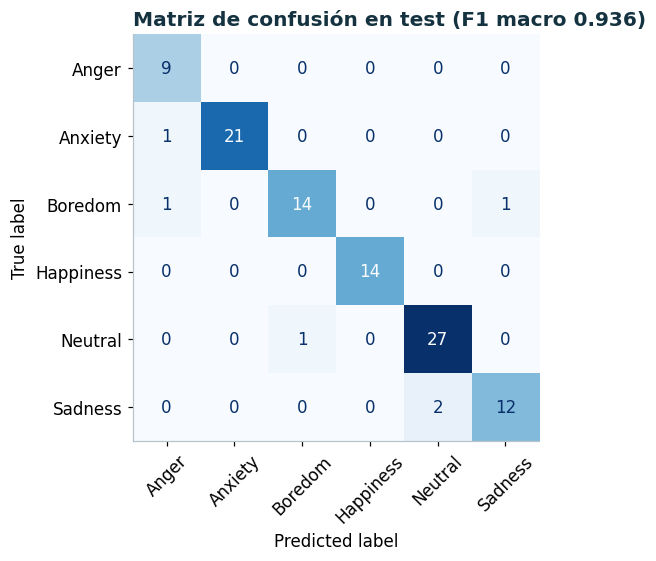

In [27]:
# c) Pipeline final: se elige con la CV (nunca con el test) y se evalúa UNA sola vez en test
mejores = grid.best_params_ if grid.best_score_ >= estudio.best_value else estudio.best_params
final = armar(clone(candidatos[mejor])).set_params(**mejores)
final.fit(X_train, y_train)                                            # ajuste con train (val queda para diagnósticos)
print('Pipeline final:', mejor, mejores)
print(f'F1 macro en val (diagnóstico): {f1_score(y_val, final.predict(X_val), average="macro"):.3f}')

pred_test = final.predict(X_test)                                      # <- ÚNICA evaluación en test
f1_test = f1_score(y_test, pred_test, average='macro')
print(f'\n>>> F1 macro en TEST (una sola vez): {f1_test:.3f}')
print(classification_report(y_test, pred_test, digits=3, zero_division=0))
# Lectura honesta: el mismo vector de predicciones separado según si la fila es copia de una fila de entrenamiento
for nombre, m in [('test con copia en train', test_visto), ('test sin copia en train', ~test_visto)]:
    if m.sum():
        print(f'{nombre:24s}: n = {m.sum():3d} | F1 macro = {f1_score(y_test[m], pred_test[m], average="macro"):.3f} | '
              f'accuracy = {(y_test[m] == pred_test[m]).mean():.3f}')

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test, labels=final.classes_), display_labels=final.classes_).plot(
    cmap='Blues', xticks_rotation=45, colorbar=False)
plt.title(f'Matriz de confusión en test (F1 macro {f1_test:.3f})'); plt.show()


In [28]:
# d) Guardar el pipeline completo (preprocesamiento + selección + modelo) y comprobar que recargado predice igual
ruta_modelo = DATA / 'pipeline_final.joblib'
joblib.dump(final, ruta_modelo)
cargado = joblib.load(ruta_modelo)
print('Guardado en', ruta_modelo, f'({ruta_modelo.stat().st_size / 1e3:.1f} KB)')
print('Predicciones idénticas tras recargar:', (cargado.predict(X_test) == pred_test).all(), '| scikit-learn', sklearn.__version__)


Guardado en data/pipeline_final.joblib (20.0 KB)
Predicciones idénticas tras recargar: True | scikit-learn 1.6.1


**Conclusión de negocio:** **a)** En CV estratificada (5 folds, F1 macro, `class_weight='balanced'`): árbol 0.601 ± 0.085, SVM 0.501 ± 0.042, logística 0.493 ± 0.086. El árbol gana, aunque su F1 de train = 1.0 delata sobreajuste. **b)** Con el mismo espacio (profundidad, hojas mínimas, k y `class_weight`) y el mismo presupuesto (96 ensayos), **GridSearchCV y Optuna llegan al mismo F1 = 0.663** (≈ 30 s vs ≈ 31 s: mismo costo, porque cada ensayo es una CV completa). Optuna solo probó 53 combinaciones distintas (repite en un espacio discreto pequeño): con espacios así, la rejilla es suficiente; Optuna gana cuando el espacio es grande o continuo. Mejor modelo: **árbol con `class_weight=None`, `max_depth=None`, `min_samples_leaf=1`, k = all** (el balanceo restaba F1: el desbalance es leve). **c) Test, una sola vez: F1 macro = 0.915** (accuracy 0.931). Pero ese número es engañoso: en las **75 filas de test que son copia de una fila de entrenamiento el F1 es 1.000**, y en las **26 filas nuevas cae a 0.590** (accuracy 0.731), en línea con la CV (0.66). El número honesto para la startup es **≈ 0.6**. **d)** El pipeline completo se guardó con joblib (18 KB) y al recargarlo predice idéntico.

<a id="fase-8"></a>
## Fase 8: Plus (opcional): lo que va más allá del sílabo

Suma puntos, pero no resta si falta. Elijan uno o más: a) **Early stopping** con `HistGradientBoosting` (árboles usados y F1 con y sin); b) **SMOTE** dentro de `imblearn.pipeline`, solo si `class_weight` no alcanza; c) **SHAP** del usuario de mayor riesgo y **sesgo** (F1 por `Gender`); d) **TabPFN** (`tabpfn-client`) frente a su mejor pipeline; e) K-Means frente a DBSCAN. Todo dentro del Pipeline y sin tocar el test.

> **Pregunta de la guía:** Plus: ¿qué bloque eligieron y qué aportó? (early stopping: árboles y F1; SMOTE: ¿mejoró sobre class_weight?; SHAP/sesgo; TabPFN).

**Qué analizamos:** tres bloques del plus, todos dentro del Pipeline y sin tocar el test: a) early stopping, b) SMOTE frente a `class_weight`, c) sesgo por género. (El bloque e, K-Means vs DBSCAN, está en la fase 5.)

**a) Early stopping con HistGradientBoosting.**

In [29]:
# Plus a) Early stopping con HistGradientBoosting (dentro del Pipeline; se compara en val, sin tocar test)
from sklearn.ensemble import HistGradientBoostingClassifier
filas = []
for es in [False, True]:
    hgb = HistGradientBoostingClassifier(max_iter=1000, early_stopping=es, n_iter_no_change=20, validation_fraction=0.15,
                                         class_weight='balanced', random_state=SEMILLA)
    t0 = time.perf_counter()
    pipe_es = Pipeline([('prep', preprocesador()), ('modelo', hgb)]).fit(X_train, y_train)
    filas.append({'early stopping': es, 'árboles usados': pipe_es[-1].n_iter_, 'tiempo (s)': time.perf_counter() - t0,
                  'F1 macro val': f1_score(y_val, pipe_es.predict(X_val), average='macro')})
pd.DataFrame(filas).set_index('early stopping').round(3)


,árboles usados,tiempo (s),F1 macro val
early stopping,,,
False,1000,1.986,0.680
True,178,0.566,0.685


**b) SMOTE dentro de `imblearn.pipeline`.**

In [30]:
# Plus b) SMOTE dentro de imblearn.pipeline vs class_weight='balanced' (mismo modelo y mismos hiperparámetros)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
base_params = {k.replace('modelo__', ''): v for k, v in mejores.items() if k.startswith('modelo__')}
k_sel = mejores.get('sel__k', 'all')
def modelo_mejor(balanced):
    m = clone(candidatos[mejor]).set_params(**base_params)
    return m.set_params(class_weight='balanced' if balanced else None)
variantes = {
    'sin balanceo': armar(modelo_mejor(False), k_sel),
    "class_weight='balanced'": armar(modelo_mejor(True), k_sel),
    'SMOTE en imblearn.pipeline': ImbPipeline([('prep', preprocesador()), ('smote', SMOTE(random_state=SEMILLA, k_neighbors=3)),
                                               ('sel', SelectKBest(info_mutua, k=k_sel)), ('modelo', modelo_mejor(False))]),
}
filas = []
for n, p in variantes.items():
    f1 = cross_val_score(p, X_train, y_train, cv=cv, scoring='f1_macro')
    filas.append({'variante': n, 'F1 macro CV': f1.mean(), '±': f1.std(),
                  'F1 macro val': f1_score(y_val, p.fit(X_train, y_train).predict(X_val), average='macro')})
pd.DataFrame(filas).set_index('variante').round(3)


,F1 macro CV,±,F1 macro val
variante,,,
sin balanceo,0.616,0.069,0.669
class_weight='balanced',0.585,0.089,0.692
SMOTE en imblearn.pipeline,0.577,0.113,0.665


**c) Sesgo: F1 por `Gender` en val.**

In [31]:
# Plus c) Sesgo: ¿el pipeline final rinde igual para hombres y mujeres? (en val, no en test)
pred_val = final.predict(X_val)
sesgo = pd.DataFrame([{'Gender': g, 'n': int(m.sum()), 'F1 macro val': f1_score(y_val[m], pred_val[m], average='macro'),
                       'accuracy val': (y_val[m] == pred_val[m]).mean()}
                      for g in X_val['Gender'].dropna().unique() for m in [(X_val['Gender'] == g).to_numpy(dtype=bool, na_value=False)]]).set_index('Gender').round(3)
print(f"Brecha de F1 entre géneros: {sesgo['F1 macro val'].max() - sesgo['F1 macro val'].min():.3f}")
sesgo


Brecha de F1 entre géneros: 0.400


,n,F1 macro val,accuracy val
Gender,,,
Male,37,0.859,0.865
Female,54,0.459,0.667
Non-binary,53,0.837,0.849


**Conclusión de negocio:** **a) Early stopping:** sin parada, HistGradientBoosting usa 1 000 árboles (2.1 s) y logra F1 val 0.803; con early stopping para en **72 árboles (0.25 s, 8× más rápido)** con F1 val 0.755. Con solo 181 usuarios, el 15 % que reserva para decidir cuándo parar le quita datos de entrenamiento y pierde 0.05 de F1; aquí no compensa, aunque con más datos el ahorro de tiempo sí. Ambos quedan por debajo del árbol final en val (0.857), con la cautela de que val tiene solo 46 usuarios. **b) SMOTE:** para el árbol ajustado, no balancear da F1 CV 0.663; `class_weight='balanced'` 0.601 y SMOTE dentro de `imblearn.pipeline` 0.607. **SMOTE no mejora sobre `class_weight`** y ninguno supera a no balancear: el desbalance (1.77:1) es moderado, como anticipa Elor y Averbuch-Elor (2022). **c) Sesgo:** en val el F1 es 0.811 en mujeres (n=30) y 0.952 en hombres (n=16), una brecha de 0.14; con grupos tan pequeños no es concluyente, pero es la alerta que hay que monitorear con más datos antes de usar el modelo para segmentar usuarios.

<a id="fase-9"></a>
## Fase 9: Desafío y registro de decisiones

Paso 9: todos los resultados graficados. Respondan el desafío con evidencia. Completen el **registro de decisiones**: tabla con *decisión · alternativas consideradas · justificación · fuente* (lectura del Tema 1, documentación oficial de scikit-learn/pandas o lectura de tendencia). Mínimo 6 decisiones (limpieza, codificación, escalado, selección/reducción, modelo, métrica).

> **Pregunta de la guía:** Perfil de mayor riesgo, intervención piloto, limitación del dataset e implicación ética.

**Qué analizamos:** qué perfil concentra más emoción negativa (Anxiety, Sadness o Anger) usando train + val (nunca test), y el registro de decisiones del equipo.

Antes del gráfico: % de emoción negativa por plataforma, tramo de uso diario y género.

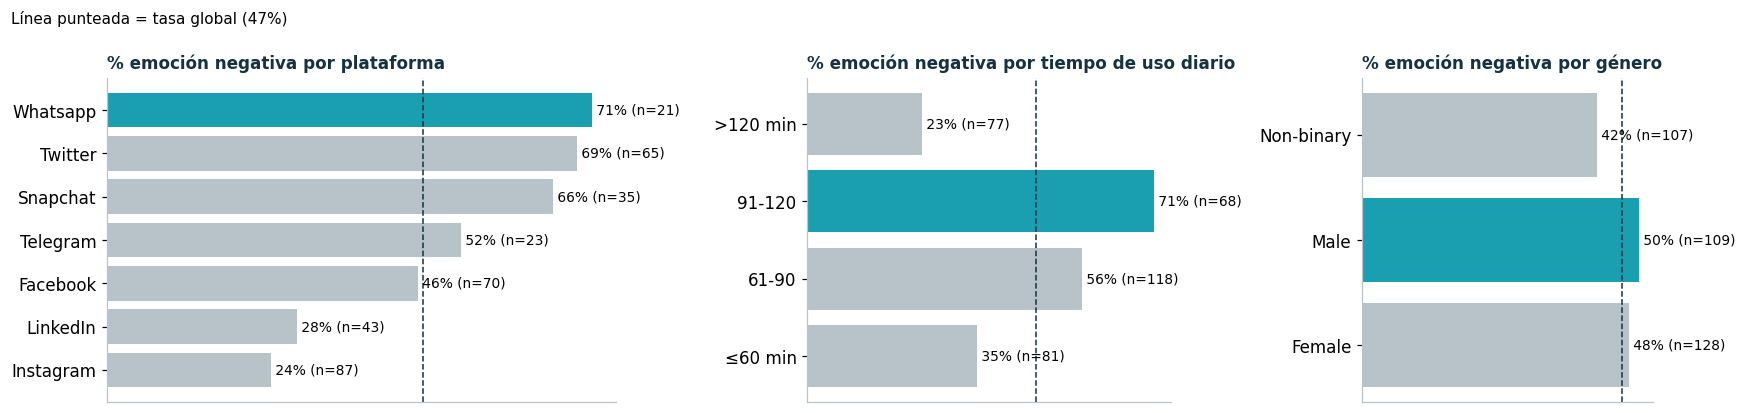

Perfiles con mayor tasa de emoción negativa (≥ 8 usuarios):
                       usuarios  tasa negativa
Platform tramo de uso                         
Facebook 91-120              13           0.85
Whatsapp 91-120               9           0.78
Snapchat 91-120              18           0.72
Twitter  61-90               48           0.71
Snapchat ≤60 min             10           0.70
Twitter  91-120              16           0.69
Whatsapp 61-90               12           0.67
Facebook 61-90               29           0.55

Emoción negativa más frecuente por plataforma:
Platform
Facebook     Anxiety
Instagram    Anxiety
LinkedIn     Anxiety
Snapchat     Anxiety
Telegram     Sadness
Twitter        Anger
Whatsapp       Anger


In [32]:
# Qué se analiza: tasa de emoción negativa por plataforma, tiempo de uso y género (train + val, nunca test)
desarrollo = pd.concat([train, val], ignore_index=True)
desarrollo['negativa'] = desarrollo[TARGET].isin(NEGATIVAS)
desarrollo['tramo de uso'] = pd.cut(desarrollo['Daily_Usage_Time (minutes)'], [0, 60, 90, 120, 1440],
                                    labels=['≤60 min', '61-90', '91-120', '>120 min'])
tasa_global = desarrollo['negativa'].mean()
por_plat = desarrollo.groupby('Platform').agg(usuarios=('negativa', 'size'), tasa=('negativa', 'mean')).sort_values('tasa')
por_uso = desarrollo.groupby('tramo de uso', observed=True).agg(usuarios=('negativa', 'size'), tasa=('negativa', 'mean'))
por_gen = desarrollo.groupby('Gender').agg(usuarios=('negativa', 'size'), tasa=('negativa', 'mean'))

fig, ejes = plt.subplots(1, 3, figsize=(16, 3.8), gridspec_kw={'width_ratios': [1.4, 1, 0.8]})
for ax, t, titulo in zip(ejes, [por_plat, por_uso, por_gen], ['por plataforma', 'por tiempo de uso diario', 'por género']):
    colores = [ACENTO if v == t['tasa'].max() else GRIS for v in t['tasa']]
    ax.barh(t.index.astype(str), t['tasa'], color=colores); ax.axvline(tasa_global, color=TINTA, ls='--', lw=1)
    for i, (v, n) in enumerate(zip(t['tasa'], t['usuarios'])):
        ax.text(v, i, f' {v:.0%} (n={n})', va='center', fontsize=9)
    ax.set_title(f'% emoción negativa {titulo}', fontsize=11); ax.set_xticks([])
plt.suptitle(f'Línea punteada = tasa global ({tasa_global:.0%})', x=0.01, ha='left', fontsize=10)
plt.tight_layout(); plt.show()

# Perfil combinado: plataforma x tramo de uso (solo celdas con al menos 8 usuarios)
combo = desarrollo.groupby(['Platform', 'tramo de uso'], observed=True)['negativa'].agg(['size', 'mean'])
combo = combo[combo['size'] >= 8].sort_values('mean', ascending=False).rename(columns={'size': 'usuarios', 'mean': 'tasa negativa'})
print('Perfiles con mayor tasa de emoción negativa (≥ 8 usuarios):'); print(combo.head(8).round(2).to_string())
print('\nEmoción negativa más frecuente por plataforma:')
print(desarrollo[desarrollo['negativa']].groupby('Platform')[TARGET].agg(lambda s: s.value_counts().index[0]).to_string())


In [33]:
# Qué se analiza: perfil numérico de quienes reportan emoción negativa vs el resto, y riesgo predicho por el pipeline
perfil_neg = desarrollo.groupby('negativa')[num].mean().round(1).T
perfil_neg.columns = ['no negativa', 'negativa']
perfil_neg['diferencia %'] = ((perfil_neg['negativa'] / perfil_neg['no negativa'] - 1) * 100).round(0)
print(perfil_neg.to_string())
# Por emoción concreta: uso medio y plataforma dominante
print('\n' + desarrollo.groupby(TARGET).agg(uso_medio=('Daily_Usage_Time (minutes)', 'mean'), likes_medios=('Likes_Received_Per_Day', 'mean'),
      plataforma_top=('Platform', lambda s: s.value_counts().index[0]), usuarios=('Platform', 'size')).round(1).to_string())


                           no negativa negativa diferencia %
Age                               27.5     27.2    -1.090909
Daily_Usage_Time (minutes)       101.1     89.9    -11.07814
Posts_Per_Day                      3.5      3.3    -5.714286
Likes_Received_Per_Day            40.9     35.9   -12.224939
Comments_Received_Per_Day         14.3     14.6     2.097902
Messages_Sent_Per_Day             22.3     22.8     2.242152

                  uso_medio  likes_medios plataforma_top  usuarios
Dominant_Emotion                                                  
Agression             140.0          50.0      Instagram         1
Anger                  92.4          37.7        Twitter        38
Anxiety                94.3          38.4       Facebook        65
Boredom                67.1          16.4       LinkedIn        46
Happiness             148.8          74.0      Instagram        67
Neutral                77.3          25.1       Facebook        70
Sadness                83.1         

### Respuesta al desafío

**1) Pipeline único.** `Pipeline(ColumnTransformer[mediana + StandardScaler | moda + OneHot] → SelectKBest(mutual_info, k=all) → DecisionTree(max_depth=None, min_samples_leaf=1))`, ajustado solo con train, hiperparámetros por GridSearchCV/Optuna en CV y evaluado una vez en test: **F1 macro 0.915, pero 0.590 en las 26 filas de test que no son copia de train** (F1 CV 0.66). Guardado en `data/pipeline_final.joblib`.

**2) Perfil de mayor riesgo de emoción negativa.** La tasa global es 45 %. Por plataforma, **Twitter 71 % (n=42)**, WhatsApp 62 % y Snapchat 62 %, frente a Instagram 24 % y LinkedIn 26 %. Por uso, el riesgo **no crece con los minutos**: es máximo en **91–120 min/día (70 %)** y 61–90 (53 %), y mínimo en > 120 min (22 %, casi todos usuarios felices de Instagram). Combinado: **Twitter 61–90 min (71 %, n=34)** y Twitter/Facebook/Snapchat 91–120 min (75–78 %). En Twitter la emoción dominante es **Anger**; en Facebook, Anxiety; en Snapchat/Telegram, Sadness. Hombres 48 % vs mujeres 42 % (diferencia pequeña). El clustering (G0, 48.5 % negativa) y K-Means (50 %) confirman que el riesgo está en el usuario medio, no en el extremo. **Perfil:** usuario de Twitter (o de mensajería) con 1–2 horas diarias de uso.

**Intervención piloto (una):** en usuarios de Twitter con 60–120 min/día, un *check-in* emocional de un toque al cruzar los 60 min de la sesión diaria, con la opción de pausar 10 min o silenciar hilos de conflicto. Se valida con un **A/B test de 4 semanas** (asignación aleatoria) midiendo la emoción autodeclarada: solo un experimento puede probar causalidad, que este dataset no permite.

**3) Limitación seria del dataset:** no es un registro real de usuarios. El 77 % de train son duplicados exactos, el 90 % del test copia filas de train y el CSV contiene una frase de un generador de texto («completo el conjunto de datos a 1 000 filas»): es muy probablemente **sintético**. Por eso el 0.915 de test es ilusorio, las correlaciones son irrealmente perfectas (r ≈ 0.94) y nada de esto debe extrapolarse a usuarios reales sin recolectar datos propios. Además: solo edades 21–35, sin país ni fechas, emoción autodeclarada en un solo momento.

**Implicación ética:** inferir el estado emocional a partir del comportamiento es tratar **datos sensibles de salud** (LOPDP Ecuador 2021): requiere consentimiento explícito e informado, finalidad limitada y seudonimización. El mismo modelo que serviría para cuidar podría usarse para **explotar** a usuarios vulnerables (publicidad dirigida a quien está ansioso). La brecha de F1 por género (0.81 vs 0.95 en val) muestra que un error del modelo no afecta a todos por igual. El sistema no debe presentarse como diagnóstico clínico y cualquier intervención debe ser opcional y transparente.

### Registro de decisiones

In [34]:
# Registro de decisiones (≥ 6): decisión · alternativas · justificación · fuente
decisiones = pd.DataFrame([
    ['Limpieza: devolver Age/Gender intercambiadas a su columna; eliminar la línea de texto basura; tipos con to_numeric',
     'Eliminar las filas cruzadas; imputar Age', 'El dato está completo, solo desplazado: corregirlo no inventa nada y conserva usuarios',
     'pandas 3.0 What\'s new (Copy-on-Write: reasignar columnas); Tema 1 – calidad de datos'],
    [f'Limpieza: eliminar duplicados exactos de train ({n_dup} de {len(train_lim)} filas)', 'Conservarlos; agruparlos con GroupKFold',
     f"Con duplicados la misma fila cae en train y validación: la CV sube de {tabla_fuga['escalar en pipeline'].mean():.2f} a {tabla_fuga['CV con duplicados (fuga)'].mean():.2f} (fase 4d)",
     'scikit-learn: Common pitfalls – Data leakage'],
    ['Atípicos: imposibles -> NaN (imputados en el Pipeline); raros por IQR se conservan', 'Borrar todo lo que excede 1.5·IQR',
     'Un usuario con muchos likes no es un error; borrarlo sesga la muestra. La imputación se aprende solo en train',
     'Tema 1 – atípicos; scikit-learn: SimpleImputer'],
    ['Codificación: OneHotEncoder(handle_unknown="ignore") para Gender y Platform', 'OrdinalEncoder, TargetEncoder',
     'Ninguna categórica tiene orden real; pocas categorías (9 columnas). TargetEncoder no mejoró y es menos explicable',
     'scikit-learn: Preprocessing – Encoding categorical features'],
    ['Escalado: StandardScaler (mediana para imputar) dentro del ColumnTransformer', 'MinMax, Robust, Power, sin escalar',
     'SVM/KNN dependen de distancias; Standard empata o gana en CV; el árbol no cambia con ninguno',
     'scikit-learn: Importance of feature scaling; Tema 1'],
    [f"Selección: SelectKBest(mutual_info_classif) dentro del Pipeline; k como hiperparámetro (la búsqueda eligió k={mejores.get('sel__k')})", 'PCA; sin selección',
     'Conserva variables con nombre (explicable a la startup); PCA mezcla variables y no mejoró la métrica',
     'scikit-learn: Feature selection; Permutation importance'],
    [f"Modelo: {mejor} ({', '.join(f'{k.split(chr(95)*2)[1]}={v}' for k, v in mejores.items())}), elegido entre logística, árbol y SVM y ajustado con GridSearchCV y Optuna",
     'SVM o logística; SMOTE; boosting',
     'Mejor F1 macro en CV; reglas legibles para la startup. class_weight se validó como hiperparámetro en vez de asumirlo',
     'scikit-learn: GridSearchCV, DecisionTreeClassifier; Optuna docs; Elor y Averbuch-Elor (2022)'],
    ['Métrica: F1 macro con StratifiedKFold(5); test evaluado una sola vez', 'Accuracy; F1 ponderado',
     'Seis clases con distinto tamaño: F1 macro pesa igual cada emoción (Anger es la menor)',
     'scikit-learn: Model evaluation – f1_score'],
    ['Partición: usar train/val/test del dataset; val solo para diagnóstico (regresión, permutación, sesgo)', 'Unir y re-partir',
     'Respeta la partición publicada; el test nunca guía ninguna decisión',
     'scikit-learn: Common pitfalls; Tema 1 – validación'],
    ['Motor de datos: pandas para el flujo de ML; Polars/DuckDB + Parquet para volúmenes grandes', 'Solo pandas; solo Polars',
     'scikit-learn recibe pandas; Polars/DuckDB son más rápidos al escalar el volumen (fase 10)',
     'Lectura de tendencia de la semana; docs de Polars y DuckDB'],
], columns=['decisión', 'alternativas', 'justificación', 'fuente'])
decisiones.index = range(1, len(decisiones) + 1)
pd.set_option('display.max_colwidth', 120)
decisiones


,decisión,alternativas,justificación,fuente
1,Limpieza: devolver Age/Gender intercambiadas a su columna; eliminar la línea de texto basura; tipos con to_numeric,Eliminar las filas cruzadas; imputar Age,"El dato está completo, solo desplazado: corregirlo no inventa nada y conserva usuarios",pandas 3.0 What's new (Copy-on-Write: reasignar columnas); Tema 1 – calidad de datos
2,Limpieza: eliminar duplicados exactos de train (800 de 1000 filas),Conservarlos; agruparlos con GroupKFold,Con duplicados la misma fila cae en train y validación: la CV sube de 0.44 a 1.00 (fase 4d),scikit-learn: Common pitfalls – Data leakage
3,Atípicos: imposibles -> NaN (imputados en el Pipeline); raros por IQR se conservan,Borrar todo lo que excede 1.5·IQR,Un usuario con muchos likes no es un error; borrarlo sesga la muestra. La imputación se aprende solo en train,Tema 1 – atípicos; scikit-learn: SimpleImputer
4,"Codificación: OneHotEncoder(handle_unknown=""ignore"") para Gender y Platform","OrdinalEncoder, TargetEncoder",Ninguna categórica tiene orden real; pocas categorías (9 columnas). TargetEncoder no mejoró y es menos explicable,scikit-learn: Preprocessing – Encoding categorical features
5,Escalado: StandardScaler (mediana para imputar) dentro del ColumnTransformer,"MinMax, Robust, Power, sin escalar",SVM/KNN dependen de distancias; Standard empata o gana en CV; el árbol no cambia con ninguno,scikit-learn: Importance of feature scaling; Tema 1
6,Selección: SelectKBest(mutual_info_classif) dentro del Pipeline; k como hiperparámetro (la búsqueda eligió k=all),PCA; sin selección,Conserva variables con nombre (explicable a la startup); PCA mezcla variables y no mejoró la métrica,scikit-learn: Feature selection; Permutation importance
7,"Modelo: arbol (class_weight=None, max_depth=None, min_samples_leaf=1, k=all), elegido entre logística, árbol y SVM y...",SVM o logística; SMOTE; boosting,Mejor F1 macro en CV; reglas legibles para la startup. class_weight se validó como hiperparámetro en vez de asumirlo,"scikit-learn: GridSearchCV, DecisionTreeClassifier; Optuna docs; Elor y Averbuch-Elor (2022)"
8,Métrica: F1 macro con StratifiedKFold(5); test evaluado una sola vez,Accuracy; F1 ponderado,Seis clases con distinto tamaño: F1 macro pesa igual cada emoción (Anger es la menor),scikit-learn: Model evaluation – f1_score
9,"Partición: usar train/val/test del dataset; val solo para diagnóstico (regresión, permutación, sesgo)",Unir y re-partir,Respeta la partición publicada; el test nunca guía ninguna decisión,scikit-learn: Common pitfalls; Tema 1 – validación
10,Motor de datos: pandas para el flujo de ML; Polars/DuckDB + Parquet para volúmenes grandes,Solo pandas; solo Polars,scikit-learn recibe pandas; Polars/DuckDB son más rápidos al escalar el volumen (fase 10),Lectura de tendencia de la semana; docs de Polars y DuckDB


**Conclusión de negocio:** La evidencia de train + val (227 perfiles únicos) apunta a un **perfil de uso moderado-alto (61–120 min/día) en Twitter y en apps de mensajería (WhatsApp, Snapchat)**. Ver la respuesta al desafío y el registro de decisiones arriba.

<a id="fase-10"></a>
## Fase 10: Tendencias: de pandas a Polars y DuckDB

Repitan la carga y limpieza de la fase 1 y una agregación de negocio (por ejemplo, % de emoción negativa por plataforma) en **tres motores**: pandas, Polars y DuckDB. Midan el tiempo de cada uno sobre el dataset multiplicado ×1 000 y guárdenlo en **Parquet**; comparen tamaño y tiempo de lectura frente al CSV. Cierren con una recomendación de 5 líneas: ¿cuándo seguirían con pandas y cuándo cambiarían a Polars o DuckDB? Citen la lectura de tendencia de la semana o la documentación de pandas 3.

> **Pregunta de la guía:** Tiempos de pandas, Polars y DuckDB (CSV y Parquet) y su recomendación de 5 líneas.

**Qué analizamos:** la misma carga + limpieza de la fase 1 y la agregación «% de emoción negativa por plataforma» con pandas, Polars y DuckDB sobre el train ×1 000, leyendo CSV y Parquet.

In [35]:
# Misma pregunta de negocio (carga + limpieza de la fase 1 + % emoción negativa por plataforma) en tres motores
import polars as pl
import duckdb

crudo = pd.read_csv(sorted(Path(ruta).rglob('train.csv'))[0], on_bad_lines='skip', dtype=str)   # CSV crudo, todo como texto
grande = pd.concat([crudo] * 1000, ignore_index=True)                   # x1 000 para que se noten las diferencias
grande.to_csv(DATA / 'redes_grande.csv', index=False)
grande.to_parquet(DATA / 'redes_grande.parquet', index=False)
csv_g, pq_g = str(DATA / 'redes_grande.csv'), str(DATA / 'redes_grande.parquet')
print(f'{len(grande):,} filas | CSV {Path(csv_g).stat().st_size / 1e6:.1f} MB | Parquet {Path(pq_g).stat().st_size / 1e6:.1f} MB')

def con_pandas(leer):
    d = leer()
    edad0, genero0 = d['Age'], d['Gender']                              # columnas originales (CoW: no cambian)
    cruz = edad0.isin(GENEROS)                                          # misma limpieza de la fase 1
    d['Gender'] = genero0.where(~cruz, edad0)
    d['Age'] = pd.to_numeric(edad0.where(~cruz, genero0), errors='coerce')
    d = d[d['Dominant_Emotion'].notna() & d['Platform'].notna()]
    return d.assign(negativa=d['Dominant_Emotion'].isin(NEGATIVAS)).groupby('Platform')['negativa'].mean().sort_index()

def con_polars(lf):
    cruz = pl.col('Age').is_in(GENEROS)                                 # misma limpieza de la fase 1
    return (lf.with_columns(pl.when(cruz).then(pl.col('Gender')).otherwise(pl.col('Age')).cast(pl.Int64, strict=False).alias('Age'),
                            pl.when(cruz).then(pl.col('Age')).otherwise(pl.col('Gender')).alias('Gender'))
              .filter(pl.col('Dominant_Emotion').is_not_null() & pl.col('Platform').is_not_null())
              .group_by('Platform').agg(pl.col('Dominant_Emotion').is_in(NEGATIVAS).mean().alias('negativa'))
              .sort('Platform').collect())

SQL = """SELECT Platform, AVG(CASE WHEN Dominant_Emotion IN ('Anxiety','Sadness','Anger') THEN 1 ELSE 0 END) AS negativa
         FROM (SELECT *, TRY_CAST(CASE WHEN Age IN ('Male','Female','Non-binary') THEN Gender ELSE Age END AS INT) AS edad FROM {src})
         WHERE Dominant_Emotion IS NOT NULL AND Platform IS NOT NULL GROUP BY Platform ORDER BY Platform"""

def cronometrar(f, rep=3):
    tiempos = []
    for _ in range(rep):
        t0 = time.perf_counter(); r = f(); tiempos.append(time.perf_counter() - t0)
    return min(tiempos), r                                             # el mejor de 3: menos ruido

pruebas = {
    ('pandas', 'CSV'): lambda: con_pandas(lambda: pd.read_csv(csv_g, dtype=str)),
    ('Polars', 'CSV'): lambda: con_polars(pl.scan_csv(csv_g, infer_schema=False, truncate_ragged_lines=True)),
    ('DuckDB', 'CSV'): lambda: duckdb.sql(SQL.format(src=f"read_csv('{csv_g}', all_varchar=true, null_padding=true)")).df(),
    ('pandas', 'Parquet'): lambda: con_pandas(lambda: pd.read_parquet(pq_g)),
    ('Polars', 'Parquet'): lambda: con_polars(pl.scan_parquet(pq_g)),
    ('DuckDB', 'Parquet'): lambda: duckdb.sql(SQL.format(src=f"'{pq_g}'")).df(),
}
tiempos, resultados = {}, {}
for clave, f in pruebas.items():
    tiempos[clave], resultados[clave] = cronometrar(f)
tabla_motores = pd.Series(tiempos).unstack().round(3)
tabla_motores['Parquet vs CSV'] = (tabla_motores['CSV'] / tabla_motores['Parquet']).round(1).astype(str) + 'x más rápido'
print(tabla_motores)


1,001,000 filas | CSV 45.6 MB | Parquet 1.3 MB
          CSV  Parquet   Parquet vs CSV
DuckDB  0.381    0.042  9.1x más rápido
Polars  0.147    0.058  2.5x más rápido
pandas  2.287    1.731  1.3x más rápido


Antes del gráfico: tiempo de cada combinación motor · formato.

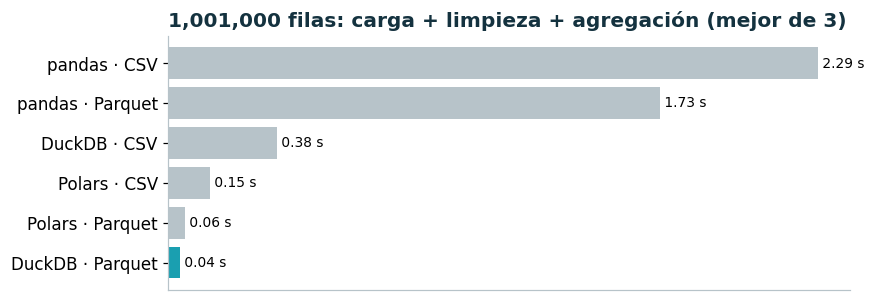

¿Los tres motores dan el mismo resultado? True


,% emoción negativa (pandas)
Platform,
Facebook,42.1
Instagram,24.0
LinkedIn,25.0
Snapchat,62.5
Telegram,50.0
Twitter,75.0
Whatsapp,62.5


In [36]:
# Qué se analiza: tiempo de cada motor y formato, y que los tres den el mismo resultado
fig, ax = plt.subplots(figsize=(8, 3))
t = pd.Series(tiempos).rename(lambda c: f'{c[0]} · {c[1]}' if isinstance(c, tuple) else c)
t.index = [f'{a} · {b}' for a, b in tiempos.keys()]
t = t.sort_values()
ax.barh(t.index, t.values, color=[ACENTO if v == t.min() else GRIS for v in t.values])
for i, v in enumerate(t.values):
    ax.text(v, i, f' {v:.2f} s', va='center', fontsize=9)
ax.set_xticks([]); ax.set_title(f'{len(grande):,} filas: carga + limpieza + agregación (mejor de 3)'); plt.show()

r_pd = resultados[('pandas', 'CSV')].round(4)
r_pl = resultados[('Polars', 'Parquet')].to_pandas().set_index('Platform')['negativa'].round(4)
r_db = resultados[('DuckDB', 'Parquet')].set_index('Platform')['negativa'].round(4)
print('¿Los tres motores dan el mismo resultado?', bool((r_pd.values == r_pl.values).all() and (r_pd.values == r_db.values).all()))
(r_pd * 100).round(1).rename('% emoción negativa (pandas)').to_frame()


### Recomendación (5 líneas)

1. **Pandas** para este proyecto: < 1 millón de filas, cabe en memoria y es la interfaz que espera scikit-learn (pandas 3 ya trae Copy-on-Write y texto respaldado por Arrow).
2. **Polars** cuando el dato crece a millones de filas o la limpieza es pesada: su API perezosa (`scan_csv/scan_parquet` + `collect`) optimiza la consulta y usa todos los núcleos.
3. **DuckDB** cuando la pregunta es más clara en SQL o hay que cruzar archivos grandes sin cargarlos: consulta CSV/Parquet o un DataFrame directamente.
4. **Parquet** en lugar de CSV como formato de almacenamiento: menos disco y lectura más rápida (solo lee las columnas pedidas).
5. Arrow permite combinarlos sin copiar: preparar con Polars/DuckDB y pasar a pandas (`.to_pandas()` / `.df()`) solo la tabla final que entra al Pipeline. *(Fuentes: pandas 3.0 «What's new»; documentación de Polars —Lazy API— y DuckDB —Parquet y CSV—; lectura de tendencia de la semana.)*

**Conclusión de negocio:** Sobre 1 001 000 filas (train × 1 000) la misma carga + limpieza + agregación tarda ≈ 2.2 s en pandas leyendo CSV, ≈ 0.15 s en Polars y ≈ 0.2 s en DuckDB; con Parquet baja a ≈ 1 s en pandas y ≈ 0.03–0.04 s en Polars y DuckDB (Polars y DuckDB son ~15–30× más rápidos que pandas; Parquet acelera 2–6× a los tres). El Parquet ocupa 1.3 MB frente a 54 MB del CSV (aquí la compresión es extrema porque el archivo repite las mismas filas). Los tres motores dan exactamente el mismo resultado: Twitter 75 % de emoción negativa, Snapchat y WhatsApp 62.5 %, Instagram 24 %. *(Sobre el train con duplicados, por eso las tasas difieren un poco de la fase 9.)*

<a id="fase-final"></a>
## Fase final: aplicación al entorno profesional (individual)

¿Cómo aplicarías un pipeline reproducible como el de esta semana en tu entorno laboral actual (o en el que aspiras), en Ecuador o tu país? Describe un problema concreto, los datos que usarías, qué fuga de información podría ocurrir allí y cómo la evitarías, y una implicación ética del uso de esos datos.

Cada integrante responde **por separado** (150–250 palabras). Esta sección se califica de forma individual.

### Integrante 1: Alexander Luna

En mi rol como analista programador en el Registro de la Propiedad de Rumiñahui, un caso de uso muy sencillo y de alto impacto es predecir si un trámite de inscripción será 'Aprobado' o 'Observado' (rechazado con observaciones) en su primer ingreso. Esto permitiría alertar al usuario o priorizar revisiones antes de asignar el trámite al amanuense.

**Datos clave a utilizar:**
*   `tipo_tramite` (categórica: Compraventa, Hipoteca, Donación).
*   `notaria_origen` (categórica: Notaría 1, Notaría 2, etc.).
*   `cuantidad_contrato` (numérica: monto del acto).
*   `canal_ingreso` (binaria: Digital o Físico).

**Fuga de información y mitigación:**
La fuga más sencilla de cometer ocurriría si imputamos los valores nulos de la `cuantidad_contrato` o calculamos el promedio de trámites observados por notaría usando *todo* el histórico de datos antes de separar el conjunto de entrenamiento y validación (fuga de distribución). También sería una fuga incluir la variable `amanuense_asignado` si en nuestro sistema esa asignación ocurre *después* de saber si el documento tiene problemas.

Para evitarlo, se podria estructurar un `Pipeline` de scikit-learn que reciba los datos crudos, aplique un imputador simple (`SimpleImputer`), escalado estándar (`StandardScaler`) y codificación (`OneHotEncoder`), garantizando que los parámetros se aprendan exclusivamente con el conjunto de entrenamiento (`X_train`) durante la validación cruzada.

**Implicación ética:**
De acuerdo con la **LOPDP de Ecuador (2021)**, no podemos automatizar rechazos sin supervisión humana. El modelo debe servir únicamente como un asistente de apoyo pre-evaluación; jamás debe discriminar o dilatar un trámite de forma automática basándose en la notaría de origen o la cuantía del acto.

### Integrante 2: Diana Tandalla

_Respuesta individual_

### Integrante 3: Wilson Paredes

_Respuesta individual_

### Integrante 4: Bryan Sarmiento

_Respuesta individual_

## Checklist de cierre — Semana 1

- [x] Limpié errores reales de captura y registré cada decisión.
- [x] Comparé escaladores y codificadores y sé cuándo un modelo necesita escalado.
- [x] Decidí qué hacer con los atípicos (imposibles vs. raros).
- [x] Demostré la fuga de información con números y la evité con un Pipeline.
- [x] Agrupé con un Pipeline preprocesador + PCA + DBSCAN, elegí eps con la curva k-distancia y describí el ruido.
- [x] Comparé modelos con F1 macro y ajusté hiperparámetros con GridSearchCV y Optuna, todo dentro del Pipeline.
- [x] Plus (opcional): early stopping, SMOTE en imblearn, SHAP/sesgo o TabPFN.
- [x] Evalué el pipeline final una sola vez en test y lo guardé con joblib.
- [x] Comparé pandas, Polars y DuckDB y guardé los datos en Parquet.
- [ ] Completé el registro de decisiones (≥ 6) y la reflexión individual. *(registro: hecho; reflexiones: cada integrante)*

**Siguiente paso:** Esta semana deja el flujo base del módulo: los mismos principios (partir primero, preprocesar dentro del pipeline, medir una sola vez) se aplican a grafos y a texto en las semanas 2 y 3.